
# KDD: What Makes YouTube Videos Take Off?

## Exploring Content Characteristics, Early Trending Performance, and Cultural Trends

This project applies the Knowledge Discovery in Databases (KDD) methodology to investigate how YouTube video characteristics relate to popularity.

The analysis focuses on five questions:

1. Which title, topic, and thumbnail characteristics are associated with higher view counts?
2. How quickly do videos first appear in Trending after publication?
3. How do content patterns differ between the United States and South Korea?
4. How might cultural trends, memes, or current events relate to popular content?
5. What can a smaller sample of actual video content reveal about storytelling and audience appeal?

The main dataset comes from Kaggle. Additional metadata, thumbnail images, and accessible video content may be used for deeper analysis.

Trending records measure popularity among videos already selected for Trending. They do not directly measure click-through rate, watch duration, or viewer loyalty.

## 1. Selection

The Selection phase examines the available data and chooses a manageable, relevant sample for the project.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

DATA_DIR = Path("/content/drive/MyDrive/KDD_Data")

COUNTRIES = ["US", "KR"]
RANDOM_STATE = 42

for country in COUNTRIES:
    csv_path = DATA_DIR / f"{country}_youtube_trending_data.csv.zip"
    json_path = DATA_DIR / f"{country}_category_id.json"

    assert csv_path.exists(), f"Missing file: {csv_path}"
    assert json_path.exists(), f"Missing file: {json_path}"

print("All required files found.")


Mounted at /content/drive
All required files found.


In [2]:

columns = [
    "video_id",
    "title",
    "publishedAt",
    "channelId",
    "channelTitle",
    "categoryId",
    "trending_date",
    "tags",
    "view_count",
    "likes",
    "comment_count",
    "thumbnail_link"
]

frames = []

for country in COUNTRIES:
    path = DATA_DIR / f"{country}_youtube_trending_data.csv.zip"

    df = pd.read_csv(
        path,
        compression="zip",
        usecols=columns,
        low_memory=False
    )

    df["country"] = country
    frames.append(df)

data = pd.concat(frames, ignore_index=True)

print("Dataset shape:", data.shape)
print("\nRecords by country:")
print(data["country"].value_counts())

display(data.head(3))


Dataset shape: (534541, 13)

Records by country:
country
US    268787
KR    265754
Name: count, dtype: int64


,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,comment_count,thumbnail_link,country
0,3C66w5Z0ixs,I ASKED HER TO BE MY GIRLFRIEND...,2020-08-11T19:20:14Z,UCvtRTOMP2TqYqu51xNrqAzg,Brawadis,22,2020-08-12T00:00:00Z,brawadis|prank|basketball|skits|ghost|funny vi...,1514614,156908,35313,https://i.ytimg.com/vi/3C66w5Z0ixs/default.jpg,US
1,M9Pmf9AB4Mo,Apex Legends | Stories from the Outlands – “Th...,2020-08-11T17:00:10Z,UC0ZV6M2THA81QT9hrVWJG3A,Apex Legends,20,2020-08-12T00:00:00Z,Apex Legends|Apex Legends characters|new Apex ...,2381688,146739,16549,https://i.ytimg.com/vi/M9Pmf9AB4Mo/default.jpg,US
2,J78aPJ3VyNs,I left youtube for a month and THIS is what ha...,2020-08-11T16:34:06Z,UCYzPXprvl5Y-Sf0g4vX-m6g,jacksepticeye,24,2020-08-12T00:00:00Z,jacksepticeye|funny|funny meme|memes|jacksepti...,2038853,353787,40221,https://i.ytimg.com/vi/J78aPJ3VyNs/default.jpg,US


In [3]:

category_maps = {}

for country in COUNTRIES:
    path = DATA_DIR / f"{country}_category_id.json"

    with open(path, "r", encoding="utf-8") as f:
        category_json = json.load(f)

    category_maps[country] = {
        str(item["id"]): item["snippet"]["title"]
        for item in category_json["items"]
    }

data["category_name"] = [
    category_maps[country].get(str(category_id), "Unknown")
    for country, category_id in zip(
        data["country"], data["categoryId"]
    )
]

print("Top categories:")
display(data["category_name"].value_counts().head(15))


Top categories:


,count
category_name,
Entertainment,144013
Music,73898
People & Blogs,67169
Gaming,64478
Sports,51823
Comedy,30232
News & Politics,19936
Howto & Style,18450
Film & Animation,18031


In [4]:

data["published_at"] = pd.to_datetime(
    data["publishedAt"], utc=True, errors="coerce"
)

data["trending_at"] = pd.to_datetime(
    data["trending_date"], utc=True, errors="coerce"
)

data["view_count"] = pd.to_numeric(
    data["view_count"], errors="coerce"
)

data["trending_day"] = data["trending_at"].dt.date

summary = []

for country, df in data.groupby("country"):
    duplicate_count = df.duplicated(
        subset=["video_id", "trending_day"]
    ).sum()

    summary.append({
        "Country": country,
        "Records": len(df),
        "Unique Videos": df["video_id"].nunique(),
        "First Trending Date": df["trending_at"].min().date(),
        "Last Trending Date": df["trending_at"].max().date(),
        "Duplicate Video-Date Records": duplicate_count,
        "Missing Publication Dates": df["published_at"].isna().sum(),
        "Missing View Counts": df["view_count"].isna().sum()
    })

display(pd.DataFrame(summary))


,Country,Records,Unique Videos,First Trending Date,Last Trending Date,Duplicate Video-Date Records,Missing Publication Dates,Missing View Counts
0,KR,265754,28251,2020-08-12,2024-04-15,3689,0,0
1,US,268787,47142,2020-08-12,2024-04-15,4070,0,0


In [5]:

# Keep original daily records unchanged.
daily = data.copy()

# Remove exact video-date repetitions, keeping the last
# observation in the original file order.
daily = daily.drop_duplicates(
    subset=["country", "video_id", "trending_day"],
    keep="last"
)

# Find the first observed Trending record per country/video.
first_trending = (
    daily.sort_values(
        ["country", "video_id", "trending_at"],
        kind="stable"
    )
    .drop_duplicates(
        subset=["country", "video_id"],
        keep="first"
    )
    .copy()
)

first_trending["days_to_trending"] = (
    first_trending["trending_at"]
    - first_trending["published_at"]
).dt.total_seconds() / 86400

print("First Trending records:", len(first_trending))

print("\nRecords by country:")
display(first_trending["country"].value_counts())

print("\nTime from publication to first observed Trending:")
display(
    first_trending.groupby("country")[
        "days_to_trending"
    ].describe().round(2)
)

print("\nNegative time differences:")
print((first_trending["days_to_trending"] < 0).sum())


First Trending records: 75393

Records by country:


,count
country,
US,47142
KR,28251



Time from publication to first observed Trending:


,count,mean,std,min,25%,50%,75%,max
country,,,,,,,,
KR,28251.0,0.90,0.94,-0.51,0.53,0.62,0.87,26.60
US,47142.0,0.89,0.81,-0.58,0.37,0.90,1.17,29.15



Negative time differences:
2787


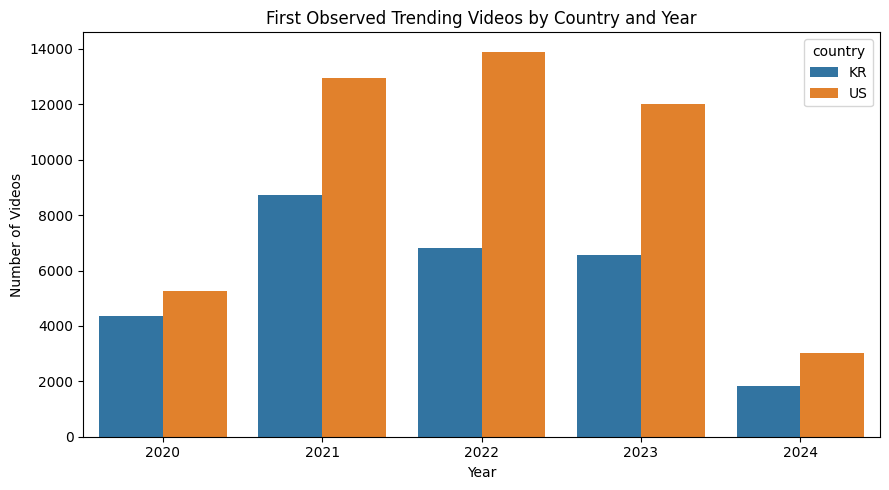

country,KR,US
year,,
2020,4370,5261
2021,8713,12953
2022,6801,13906
2023,6544,12008
2024,1823,3014


In [6]:

first_trending["year"] = (
    first_trending["trending_at"].dt.year
)

year_counts = (
    first_trending
    .groupby(["year", "country"])
    .size()
    .reset_index(name="videos")
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=year_counts,
    x="year",
    y="videos",
    hue="country"
)

plt.title("First Observed Trending Videos by Country and Year")
plt.xlabel("Year")
plt.ylabel("Number of Videos")
plt.tight_layout()
plt.show()

display(
    year_counts.pivot(
        index="year",
        columns="country",
        values="videos"
    ).fillna(0).astype(int)
)



### Selection - Initial Findings

The project uses YouTube Trending records from the United States and South Korea.

Both countries were selected to explore differences in content characteristics and cultural trends.

Because individual videos may appear in Trending on multiple dates, the dataset is examined at two levels:

- Daily Trending records for studying observed changes over time.
- First-observed Trending records for comparing individual videos.

The initial inspection checks dates, categories, duplicate records, and the time between publication and first observed Trending appearance.

The final analysis period and sample sizes will be selected after reviewing these results.

Thumbnail and actual video content analysis will be developed as additional components using smaller samples, depending on data availability.



In [7]:

# Selection Revision 1: validate timing and duplicate records

# Trending dates represent calendar days, not exact entry times.
first_trending["calendar_days_to_trending"] = (
    first_trending["trending_at"].dt.normalize()
    - first_trending["published_at"].dt.normalize()
).dt.days

print("Calendar-day differences:")
display(
    first_trending.groupby("country")[
        "calendar_days_to_trending"
    ].describe().round(2)
)

print("\nNegative calendar-day differences:")
display(
    first_trending.assign(
        negative=lambda x: x["calendar_days_to_trending"] < 0
    ).groupby("country")["negative"].sum()
)

# Examine records sharing the same country, video, and date.
duplicate_groups = (
    data.groupby(
        ["country", "video_id", "trending_day"]
    )
    .agg(
        records=("view_count", "size"),
        distinct_views=("view_count", "nunique")
    )
    .reset_index()
)

duplicate_groups = duplicate_groups[
    duplicate_groups["records"] > 1
]

print("\nDuplicate groups:")
display(
    duplicate_groups.groupby("country").agg(
        groups=("records", "size"),
        differing_view_counts=(
            "distinct_views",
            lambda s: int((s > 1).sum())
        )
    )
)

# Compare complete calendar years as candidate analysis periods.
candidate = first_trending[
    first_trending["year"].between(2021, 2023)
].copy()

print("\nCandidate period: 2021-2023")
print("Selected country-video records:", len(candidate))

display(
    candidate.groupby(["year", "country"])
    .size()
    .unstack(fill_value=0)
)


Calendar-day differences:


,count,mean,std,min,25%,50%,75%,max
country,,,,,,,,
KR,28251.0,1.30,0.95,0.0,1.0,1.0,1.0,27.0
US,47142.0,1.49,0.87,0.0,1.0,1.0,2.0,30.0



Negative calendar-day differences:


,negative
country,
KR,0
US,0



Duplicate groups:


,groups,differing_view_counts
country,,
KR,3689,3500
US,4070,3875



Candidate period: 2021-2023
Selected country-video records: 60925


country,KR,US
year,,
2021,8713,12953
2022,6801,13906
2023,6544,12008


### Selection Review - Revision 1

The initial analysis found negative time differences because Trending dates are recorded as calendar-day timestamps rather than exact entry times.

The revised analysis checks calendar-day differences and examines repeated video-date records before finalizing the data cleaning rules.

The years 2021-2023 are being considered for the main analysis because they represent complete calendar years within the available data.

The final selection rules will be confirmed after reviewing these validation results.

In [8]:

# Selection Revision 2: build a consistent analysis dataset

# Select the record with the highest observed views
# within each country-video-calendar-day group.
daily_final = (
    data.sort_values("view_count", kind="stable")
    .drop_duplicates(
        subset=["country", "video_id", "trending_day"],
        keep="last"
    )
    .copy()
)

daily_final["year"] = daily_final["trending_at"].dt.year

# Main analysis period
daily_selected = daily_final[
    daily_final["year"].between(2021, 2023)
].copy()

# One record per country and video:
# first observed Trending day, with that day's maximum views
video_selected = (
    daily_final.sort_values(
        ["country", "video_id", "trending_at"],
        kind="stable"
    )
    .drop_duplicates(
        subset=["country", "video_id"],
        keep="first"
    )
    .copy()
)

video_selected["calendar_days_to_trending"] = (
    video_selected["trending_at"].dt.normalize()
    - video_selected["published_at"].dt.normalize()
).dt.days

video_selected = video_selected[
    video_selected["trending_at"].dt.year.between(2021, 2023)
].copy()

print("Selected daily records:", len(daily_selected))
print("Selected country-video records:", len(video_selected))

print("\nVideos by country:")
display(video_selected["country"].value_counts())

print("\nSelected years:")
display(
    video_selected.groupby(
        [video_selected["trending_at"].dt.year, "country"]
    ).size().unstack(fill_value=0)
)

# Validate selection
checks = {
    "Unique daily keys": not daily_selected.duplicated(
        ["country", "video_id", "trending_day"]
    ).any(),
    "Unique video keys": not video_selected.duplicated(
        ["country", "video_id"]
    ).any(),
    "Valid years": video_selected["trending_at"].dt.year.between(
        2021, 2023
    ).all(),
    "Nonnegative calendar differences": (
        video_selected["calendar_days_to_trending"].dropna() >= 0
    ).all()
}

print("\nSelection checks:")
for name, result in checks.items():
    print(f"{name}: {'PASS' if result else 'FAIL'}")

# Candidate pool for thumbnail and content analysis
content_candidates = video_selected[
    video_selected["thumbnail_link"].notna()
    & video_selected["title"].notna()
    & video_selected["view_count"].notna()
].copy()

print("\nContent analysis candidate pool:",
      len(content_candidates))


Selected daily records: 432237
Selected country-video records: 60925

Videos by country:


,count
country,
US,38867
KR,22058



Selected years:


country,KR,US
trending_at,,
2021,8713,12953
2022,6801,13906
2023,6544,12008



Selection checks:
Unique daily keys: PASS
Unique video keys: PASS
Valid years: PASS
Nonnegative calendar differences: PASS

Content analysis candidate pool: 60925



### Selection Review - Revision 2

The main analysis period is 2021-2023, using records from the United States and South Korea.

Repeated records for the same country, video, and calendar day are consolidated by retaining the highest observed view count.

Two datasets are maintained:

- `daily_selected`: daily observations for exploring changes over time.
- `video_selected`: one first-observed Trending-day record per country and video.

The first-observed view count is a daily observation, not an exact count at the moment a video entered Trending.

A separate candidate pool is prepared for thumbnail and actual video content analysis.

The selection process is validated before moving to preprocessing.



## 2. Preprocessing

### Objective

The Preprocessing phase examines and cleans the selected YouTube Trending records before feature engineering and analysis.

This phase focuses on:

1. Checking missing values and invalid numerical records.
2. Examining view-count distributions and extreme values.
3. Checking the availability and quality of titles, tags, descriptions, and thumbnail links.
4. Preparing consistent records for later content and trend analysis.

Cleaning decisions will be made after inspecting the results. Extreme view counts will not automatically be removed because highly popular videos are relevant to the research question.


In [9]:

# Preprocessing: inspect missing values and data quality

quality_columns = [
    "title", "channelId", "category_name",
    "tags", "thumbnail_link",
    "published_at", "trending_at",
    "view_count", "likes", "comment_count"
]

quality_summary = pd.DataFrame({
    "Missing": video_selected[quality_columns].isna().sum(),
    "Missing %": (
        video_selected[quality_columns].isna().mean() * 100
    ).round(2)
})

display(quality_summary)

print("Blank titles:",
      video_selected["title"].fillna("").str.strip().eq("").sum())

print("Nonpositive view counts:",
      (video_selected["view_count"] <= 0).sum())

print("Negative likes:",
      (pd.to_numeric(
          video_selected["likes"], errors="coerce"
      ) < 0).sum())

print("Negative comments:",
      (pd.to_numeric(
          video_selected["comment_count"], errors="coerce"
      ) < 0).sum())

print("\nRecords by country:")
display(video_selected["country"].value_counts())


,Missing,Missing %
title,0,0.0
channelId,0,0.0
category_name,0,0.0
tags,0,0.0
thumbnail_link,0,0.0
published_at,0,0.0
trending_at,0,0.0
view_count,0,0.0
likes,0,0.0
comment_count,0,0.0


Blank titles: 0
Nonpositive view counts: 16
Negative likes: 0
Negative comments: 0

Records by country:


,count
country,
US,38867
KR,22058


View-count statistics by country:


,count,mean,std,min,50%,90%,95%,99%,max
country,,,,,,,,,
KR,22058.0,853541.0,2718871.0,0.0,372636.0,1449844.0,2333425.0,8789017.0,118536352.0
US,38867.0,1242557.0,2882181.0,0.0,571478.0,2433688.0,3861685.0,11622954.0,91463891.0


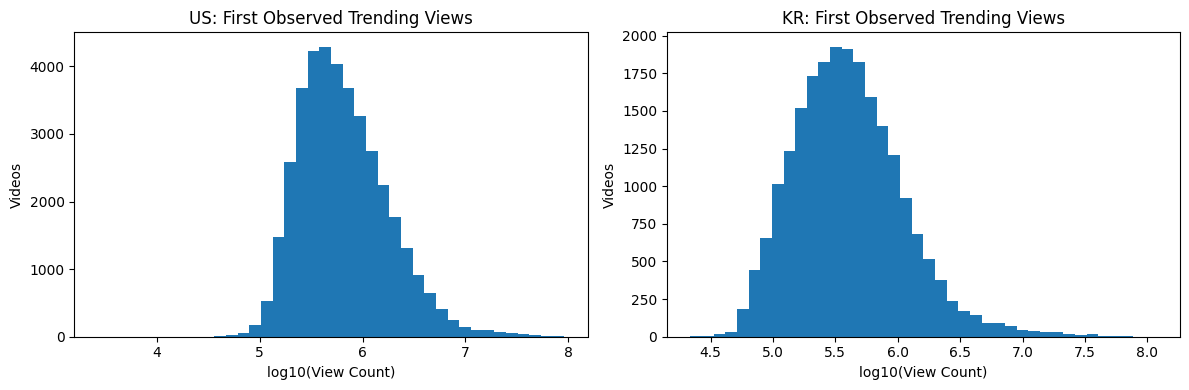

Videos above 10 million views:


,above_10m
country,
KR,193
US,466


In [10]:

# Preprocessing: inspect view-count distribution

print("View-count statistics by country:")
display(
    video_selected.groupby("country")["view_count"]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .round(0)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, country in zip(axes, COUNTRIES):
    values = video_selected.loc[
        (video_selected["country"] == country)
        & (video_selected["view_count"] > 0),
        "view_count"
    ]

    ax.hist(np.log10(values), bins=40)
    ax.set_title(f"{country}: First Observed Trending Views")
    ax.set_xlabel("log10(View Count)")
    ax.set_ylabel("Videos")

plt.tight_layout()
plt.show()

print("Videos above 10 million views:")
display(
    video_selected.assign(
        above_10m=video_selected["view_count"] > 10_000_000
    ).groupby("country")["above_10m"].sum()
)


In [11]:

# Preprocessing: inspect content metadata

content_quality = video_selected.copy()

content_quality["title_length"] = (
    content_quality["title"].fillna("").str.len()
)

content_quality["tag_available"] = (
    content_quality["tags"].fillna("").str.strip()
    .ne("")
    & content_quality["tags"].fillna("").ne("[None]")
)

content_quality["thumbnail_available"] = (
    content_quality["thumbnail_link"].fillna("")
    .str.startswith(("http://", "https://"))
)

summary = content_quality.groupby("country").agg(
    videos=("video_id", "size"),
    median_title_length=("title_length", "median"),
    tag_availability=("tag_available", "mean"),
    thumbnail_url_availability=("thumbnail_available", "mean")
)

summary["tag_availability"] *= 100
summary["thumbnail_url_availability"] *= 100

print("Content metadata quality:")
display(summary.round(2))

print("\nSample thumbnail links:")
display(
    content_quality[
        ["country", "title", "thumbnail_link"]
    ].sample(
        min(5, len(content_quality)),
        random_state=RANDOM_STATE
    )
)


Content metadata quality:


,videos,median_title_length,tag_availability,thumbnail_url_availability
country,,,,
KR,22058,42.0,86.39,100.0
US,38867,48.0,82.66,100.0



Sample thumbnail links:


,country,title,thumbnail_link
479363,KR,실시간 장마 소식 전하던 기자..,https://i.ytimg.com/vi/7ZZ6LwZDXNI/default.jpg
168598,US,Letting Shane Control The Day… An Extreme 24 H...,https://i.ytimg.com/vi/LMdo2bxg-r8/default.jpg
456547,KR,[#무한도전] 🎉경 존버당 축🎉 이게 바로 스태프도 웃참 실패한 레전드 예능이다 |...,https://i.ytimg.com/vi/Ixu0wKDl29s/default.jpg
345943,KR,패왕색과 패왕별희... 한 편의 영화(?) 같은 커플 만나고 왔습니다! 현아&던 편...,https://i.ytimg.com/vi/wT3lOeTZirw/default.jpg
302364,KR,[김선호] “제가 티켓 나눔 해드리겠습니다”⎮'얼음' 티켓팅 도전기,https://i.ytimg.com/vi/rNLTu1Waz9A/default.jpg


In [12]:

# Preprocessing: inspect description availability
# Read only necessary columns from the original CSV archives.

description_rows = []

for country in COUNTRIES:
    path = DATA_DIR / f"{country}_youtube_trending_data.csv.zip"

    desc_df = pd.read_csv(
        path,
        compression="zip",
        usecols=["video_id", "description"],
        low_memory=False
    )

    desc_df["country"] = country

    # A video's description may appear in multiple daily records.
    desc_df["description"] = (
        desc_df["description"].fillna("")
    )

    desc_df["description_length"] = (
        desc_df["description"].str.len()
    )

    desc_df = (
        desc_df.sort_values(
            "description_length",
            ascending=False,
            kind="stable"
        )
        .drop_duplicates(
            subset=["country", "video_id"],
            keep="first"
        )
    )

    description_rows.append(
        desc_df[["country", "video_id", "description"]]
    )

descriptions = pd.concat(
    description_rows, ignore_index=True
)

content_quality = content_quality.merge(
    descriptions,
    on=["country", "video_id"],
    how="left",
    validate="one_to_one"
)

content_quality["description_available"] = (
    content_quality["description"].fillna("")
    .str.strip().ne("")
)

print("Description availability by country (%):")
display(
    (content_quality.groupby("country")[
        "description_available"
    ].mean() * 100).round(2)
)

print("\nRecords after merging descriptions:",
      len(content_quality))

print("Original selected records:",
      len(video_selected))


Description availability by country (%):


,description_available
country,
KR,98.05
US,97.81



Records after merging descriptions: 60925
Original selected records: 60925


In [13]:

# Preprocessing: create an initial clean analysis table

clean_video = content_quality.copy()

# Remove records that cannot support the core analysis.
valid_core = (
    clean_video["video_id"].notna()
    & clean_video["title"].fillna("").str.strip().ne("")
    & clean_video["published_at"].notna()
    & clean_video["trending_at"].notna()
    & clean_video["view_count"].notna()
    & (clean_video["view_count"] > 0)
    & clean_video["calendar_days_to_trending"].notna()
    & (clean_video["calendar_days_to_trending"] >= 0)
)

clean_video = clean_video.loc[valid_core].copy()

# Preserve original views and add a transformed version.
clean_video["log_views"] = np.log1p(
    clean_video["view_count"]
)

print("Before cleaning:", len(content_quality))
print("After cleaning:", len(clean_video))
print("Removed:", len(content_quality) - len(clean_video))

checks = {
    "Unique country-video keys": not clean_video.duplicated(
        ["country", "video_id"]
    ).any(),
    "Valid view counts": (
        clean_video["view_count"] > 0
    ).all(),
    "Valid dates": (
        clean_video["calendar_days_to_trending"] >= 0
    ).all(),
    "Finite transformed views": np.isfinite(
        clean_video["log_views"]
    ).all()
}

print("\nPreprocessing checks:")
for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nClean videos by country:")
display(clean_video["country"].value_counts())


Before cleaning: 60925
After cleaning: 60909
Removed: 16

Preprocessing checks:
Unique country-video keys: PASS
Valid view counts: PASS
Valid dates: PASS
Finite transformed views: PASS

Clean videos by country:


,count
country,
US,38853
KR,22056



### Preprocessing - Initial Findings

The initial preprocessing analysis examines data quality, view-count distributions, and the availability of content metadata.

View counts are expected to vary substantially because the dataset contains videos with different levels of popularity. Extreme values are retained unless further inspection identifies invalid records.

Titles, tags, descriptions, and thumbnail URLs are inspected as potential sources of content-related features.

A cleaned video-level dataset is prepared by excluding records with missing essential information or invalid view counts and dates.

The original view counts are preserved, while a log-transformed version is created for later analysis.

Thumbnail URL availability does not guarantee image accessibility. Actual video content and subtitles are not included in the Kaggle dataset and will require separate feasibility checks.

The detailed findings and cleaning decisions will be updated after reviewing the execution results.


In [14]:

# Preprocessing Revision 1:
# Examine how useful the available descriptions are.

clean_video["description_length"] = (
    clean_video["description"].fillna("").str.len()
)

clean_video["description_word_count"] = (
    clean_video["description"].fillna("")
    .str.split().str.len()
)

clean_video["short_description"] = (
    clean_video["description_length"] < 50
)

clean_video["long_description"] = (
    clean_video["description_length"] >= 200
)

description_quality = clean_video.groupby("country").agg(
    videos=("video_id", "size"),
    median_description_length=("description_length", "median"),
    median_word_count=("description_word_count", "median"),
    short_descriptions=("short_description", "sum"),
    long_descriptions=("long_description", "sum")
)

print("Description quality by country:")
display(description_quality)

print("\nDescription length distribution:")
display(
    clean_video.groupby("country")["description_length"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .round(1)
)

print("\nShort description percentage:")
display(
    (clean_video.groupby("country")[
        "short_description"
    ].mean() * 100).round(2)
)


Description quality by country:


,videos,median_description_length,median_word_count,short_descriptions,long_descriptions
country,,,,,
KR,22056,283.0,33.0,1822,13783
US,38853,726.0,75.0,1442,34411



Description length distribution:


,count,mean,std,min,25%,50%,75%,90%,max
country,,,,,,,,,
KR,22056.0,393.4,441.9,0.0,137.0,283.0,489.0,808.0,4862.0
US,38853.0,995.4,892.0,0.0,392.0,726.0,1326.0,2171.0,4998.0



Short description percentage:


,short_description
country,
KR,8.26
US,3.71



### Preprocessing Review - Revision 1

The initial inspection showed that most selected videos had titles, thumbnail URLs, and descriptions available.

However, metadata availability does not guarantee useful content information.

The revised analysis examines description lengths and identifies videos with very short descriptions.

Descriptions were selected from available historical records based on length, so they may not represent the text available at the first Trending observation.

This limitation will be considered when using descriptions for later analysis.


In [15]:

# Preprocessing Revision 2:
# Test thumbnail accessibility and image dimensions.

import requests
from PIL import Image
from io import BytesIO

thumbnail_sample = (
    clean_video.groupby("country", group_keys=False)
    .sample(n=10, random_state=RANDOM_STATE)
    .copy()
)

results = []

for _, record in thumbnail_sample.iterrows():
    url = record["thumbnail_link"]

    result = {
        "country": record["country"],
        "video_id": record["video_id"],
        "accessible": False,
        "width": np.nan,
        "height": np.nan
    }

    try:
        response = requests.get(url, timeout=10)
        response.raise_for_status()

        with Image.open(BytesIO(response.content)) as img:
            img.verify()

        with Image.open(BytesIO(response.content)) as img:
            result["width"], result["height"] = img.size

        result["accessible"] = True

    except (requests.RequestException, OSError, ValueError):
        pass

    results.append(result)

thumbnail_check = pd.DataFrame(results)

print("Thumbnail accessibility:")
display(
    thumbnail_check.groupby("country").agg(
        tested=("video_id", "size"),
        accessible=("accessible", "sum"),
        median_width=("width", "median"),
        median_height=("height", "median")
    )
)

print("\nDetailed sample:")
display(thumbnail_check)


Thumbnail accessibility:


,tested,accessible,median_width,median_height
country,,,,
KR,10,9,120.0,90.0
US,10,9,120.0,90.0



Detailed sample:


,country,video_id,accessible,width,height
0,KR,PCZYPgprwFk,True,120.0,90.0
1,KR,RsxVYhn9D3A,True,120.0,90.0
2,KR,FsBr0j85Zvg,True,120.0,90.0
3,KR,SljQYJk0Zbw,True,120.0,90.0
4,KR,bZxf6zsggRM,True,120.0,90.0
5,KR,sTprt6cZnyI,True,120.0,90.0
6,KR,Kgb4sg-SCdY,False,NaN,NaN
7,KR,HhocRYYLVC4,True,120.0,90.0
8,KR,1JHOl9CSmXk,True,120.0,90.0
9,KR,z0JraysWnNw,True,120.0,90.0



### Preprocessing Review - Revision 2

The description quality analysis showed differences in description lengths between the United States and South Korea.

However, description length alone does not indicate how much meaningful information the text contains.

A reproducible sample of 10 videos per country was selected to test thumbnail accessibility and image dimensions.

This check evaluates whether thumbnail-based visual analysis is feasible. A successful URL request does not guarantee that the image contains useful visual information, and the sample is too small to establish availability across the full dataset.



## 3. Transformation

### Objective

The Transformation phase converts cleaned YouTube Trending records into features that can be used for content analysis and data mining.

The initial feature groups are:

1. Title characteristics, such as length, punctuation, and numbers.
2. Content categories and publishing time.
3. Early observed popularity and time to first observed Trending.
4. Thumbnail characteristics, subject to image availability.
5. Video descriptions and content-related keywords.

Actual video structure, storytelling, cultural trends, and subtitles will be investigated through a smaller content-analysis sample.

The analysis distinguishes features that are available before publication from information observed after publication.


In [16]:

# Transformation: create title and publishing-time features

features = clean_video.copy()

titles = features["title"].fillna("")

features["title_length"] = titles.str.len()
features["title_word_count"] = titles.str.split().str.len()
features["has_question"] = titles.str.contains(
    r"[?？]", regex=True
)
features["has_exclamation"] = titles.str.contains(
    r"[!！]", regex=True
)
features["has_number"] = titles.str.contains(
    r"\d", regex=True
)
features["hashtag_count"] = titles.str.count(r"#\S+")

features["publish_hour_utc"] = features["published_at"].dt.hour
features["publish_weekday_utc"] = (
    features["published_at"].dt.day_name()
)

print("Title feature summary:")
display(
    features.groupby("country")[
        ["title_length", "title_word_count",
         "has_question", "has_exclamation", "has_number"]
    ].agg(["median", "mean"]).round(2)
)

print("\nSample transformed features:")
display(
    features[
        ["country", "title", "title_length",
         "has_question", "has_exclamation",
         "publish_weekday_utc", "publish_hour_utc"]
    ].head(5)
)


Title feature summary:


title_length        title_word_count       has_question        \
              median   mean           median  mean       median  mean   
country                                                                 
KR              42.0  45.22              9.0  9.50          0.0  0.17   
US              48.0  50.58              8.0  8.84          0.0  0.04   

        has_exclamation       has_number        
                 median  mean     median  mean  
country                                         
KR                  0.0  0.21        0.0  0.49  
US                  0.0  0.16        0.0  0.34


Sample transformed features:


,country,title,title_length,has_question,has_exclamation,publish_weekday_utc,publish_hour_utc
0,KR,[Full] 왔다! 내 손주 - 프랑스에서 날아온 네 손주 (1),36,False,True,Friday,0
1,KR,IVE 아이브 'ELEVEN' MV,19,False,False,Wednesday,9
2,KR,그녀에게 고백을 받았습니다 In Bangkok [22],30,False,False,Saturday,8
3,KR,밥통에 사과를 넣었더니 그립던 옛맛에 눈물이 납니다,28,False,False,Thursday,4
4,KR,[ENG] [#SMTM11/1회 선공개] '피하고 싶은 스승이냐 만나고 싶은 최애냐...,80,False,False,Friday,5


In [17]:

# Transformation: prepare content and popularity features

features["category_name"] = (
    features["category_name"].fillna("Unknown")
)

features["publish_year"] = (
    features["published_at"].dt.year
)

features["first_trending_year"] = (
    features["trending_at"].dt.year
)

features["first_observed_views"] = features["view_count"]

# Observed popularity is a target/outcome, not a
# pre-publication predictor.
features["log_first_observed_views"] = np.log1p(
    features["first_observed_views"]
)

features["days_to_first_observed_trending"] = (
    features["calendar_days_to_trending"]
)

features["tag_count"] = (
    features["tags"].fillna("")
    .apply(
        lambda x: 0 if x == "[None]" or not x.strip()
        else len(x.split("|"))
    )
)

print("Category distribution:")
display(
    features.groupby(["country", "category_name"])
    .size()
    .reset_index(name="videos")
    .sort_values(["country", "videos"],
                 ascending=[True, False])
    .groupby("country")
    .head(8)
)

print("\nInitial popularity statistics:")
display(
    features.groupby("country")[
        ["first_observed_views",
         "days_to_first_observed_trending",
         "tag_count"]
    ].median().round(2)
)


Category distribution:


,country,category_name,videos
3,KR,Entertainment,7662
9,KR,People & Blogs,3568
7,KR,Music,2605
12,KR,Sports,1889
1,KR,Comedy,1292
8,KR,News & Politics,937
6,KR,Howto & Style,895
5,KR,Gaming,881
20,US,Gaming,8342
18,US,Entertainment,7606



Initial popularity statistics:


,first_observed_views,days_to_first_observed_trending,tag_count
country,,,
KR,372684.0,1.0,14.0
US,571689.0,1.0,15.0


Title patterns and observed view counts:


,country,pattern,present,videos,median_views
0,US,has_question,False,37152,580106.0
1,US,has_question,True,1701,445373.0
2,US,has_exclamation,False,32534,593834.0
3,US,has_exclamation,True,6319,483252.0
4,US,has_number,False,25518,562210.0
5,US,has_number,True,13335,596803.0
6,KR,has_question,False,18348,383222.0
7,KR,has_question,True,3708,324862.0
8,KR,has_exclamation,False,17380,395696.0
9,KR,has_exclamation,True,4676,305844.0


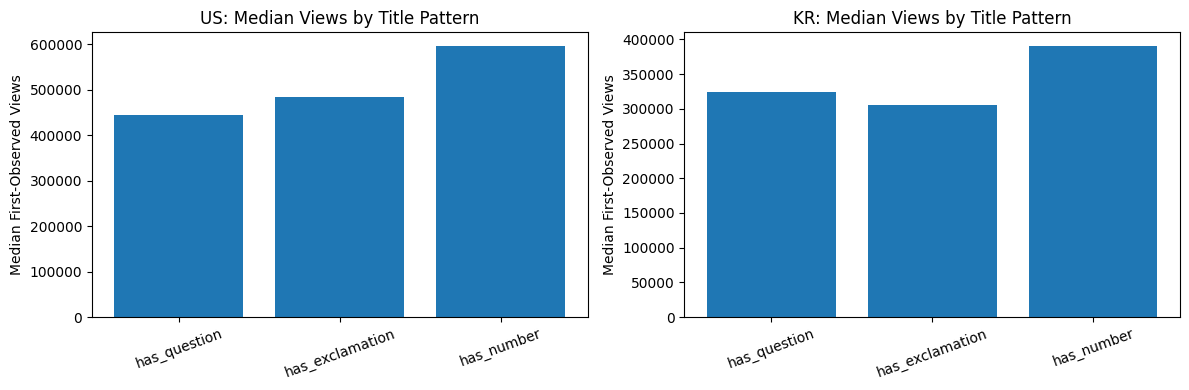

In [18]:

# Transformation: inspect simple title patterns

title_patterns = [
    "has_question",
    "has_exclamation",
    "has_number"
]

results = []

for country in COUNTRIES:
    subset = features[features["country"] == country]

    for pattern in title_patterns:
        for value in [False, True]:
            group = subset[subset[pattern] == value]

            results.append({
                "country": country,
                "pattern": pattern,
                "present": value,
                "videos": len(group),
                "median_views": group[
                    "first_observed_views"
                ].median()
            })

pattern_summary = pd.DataFrame(results)

print("Title patterns and observed view counts:")
display(pattern_summary.round(0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, country in zip(axes, COUNTRIES):
    subset = pattern_summary[
        (pattern_summary["country"] == country)
        & (pattern_summary["present"])
    ]

    ax.bar(
        subset["pattern"],
        subset["median_views"]
    )
    ax.set_title(f"{country}: Median Views by Title Pattern")
    ax.set_ylabel("Median First-Observed Views")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


In [19]:

# Transformation: test higher-resolution thumbnails

from urllib.parse import urlparse
from PIL import Image
from io import BytesIO
import requests

successful = thumbnail_check[
    thumbnail_check["accessible"]
].copy()

thumbnail_results = []

for _, row in successful.iterrows():
    video_id = row["video_id"]

    result = {
        "country": row["country"],
        "video_id": video_id,
        "variant": None,
        "width": np.nan,
        "height": np.nan,
        "usable": False
    }

    for variant in ["maxresdefault", "hqdefault", "mqdefault"]:
        url = (
            f"https://i.ytimg.com/vi/{video_id}/{variant}.jpg"
        )

        try:
            response = requests.get(url, timeout=10)
            response.raise_for_status()

            with Image.open(BytesIO(response.content)) as img:
                width, height = img.size

            # Some unavailable thumbnail variants return
            # a small placeholder instead of an HTTP error.
            if width < 320 or height < 180:
                continue

            result.update({
                "variant": variant,
                "width": width,
                "height": height,
                "usable": True
            })
            break

        except (requests.RequestException, OSError):
            continue

    thumbnail_results.append(result)

high_res_check = pd.DataFrame(thumbnail_results)

print("Higher-resolution thumbnail results:")
display(
    high_res_check.groupby("country").agg(
        tested=("video_id", "size"),
        usable=("usable", "sum"),
        median_width=("width", "median"),
        median_height=("height", "median")
    )
)

print("\nThumbnail variants:")
display(high_res_check)


Higher-resolution thumbnail results:


,tested,usable,median_width,median_height
country,,,,
KR,9,9,1280.0,720.0
US,9,9,1280.0,720.0



Thumbnail variants:


,country,video_id,variant,width,height,usable
0,KR,PCZYPgprwFk,maxresdefault,1280,720,True
1,KR,RsxVYhn9D3A,maxresdefault,1280,720,True
2,KR,FsBr0j85Zvg,maxresdefault,1280,720,True
3,KR,SljQYJk0Zbw,maxresdefault,1280,720,True
4,KR,bZxf6zsggRM,maxresdefault,1280,720,True
5,KR,sTprt6cZnyI,maxresdefault,1280,720,True
6,KR,HhocRYYLVC4,maxresdefault,1280,720,True
7,KR,1JHOl9CSmXk,maxresdefault,1280,720,True
8,KR,z0JraysWnNw,maxresdefault,1280,720,True
9,US,niG3YMU6jFk,maxresdefault,1280,720,True


In [20]:

# Transformation: validate initial features

required_features = [
    "title_length",
    "title_word_count",
    "has_question",
    "has_exclamation",
    "has_number",
    "publish_hour_utc",
    "publish_weekday_utc",
    "category_name",
    "first_observed_views",
    "log_first_observed_views",
    "days_to_first_observed_trending",
    "tag_count"
]

checks = {
    "All features created": all(
        col in features.columns for col in required_features
    ),
    "Record count preserved": len(features) == len(clean_video),
    "Unique country-video keys": not features.duplicated(
        ["country", "video_id"]
    ).any(),
    "Positive observed views": (
        features["first_observed_views"] > 0
    ).all(),
    "Valid title lengths": (
        features["title_length"] > 0
    ).all(),
    "Finite log views": np.isfinite(
        features["log_first_observed_views"]
    ).all(),
    "Valid tag counts": (
        features["tag_count"] >= 0
    ).all()
}

print("Transformation checks:")
for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nTransformed records:", len(features))
print("Feature columns created:", len(required_features))


Transformation checks:
All features created: PASS
Record count preserved: PASS
Unique country-video keys: PASS
Positive observed views: PASS
Valid title lengths: PASS
Finite log views: PASS
Valid tag counts: PASS

Transformed records: 60909
Feature columns created: 12



### Transformation - Initial Findings

The initial transformation creates features describing video titles, publishing times, categories, tags, and first-observed Trending popularity.

Title patterns are examined to explore possible relationships with view counts, but these comparisons do not establish causal effects.

The first-observed view count is treated as an outcome rather than an input for predicting popularity before publication.

A small thumbnail sample is used to test whether higher-resolution images are accessible.

Further work will investigate richer thumbnail features, cultural and topical patterns, and actual video content through a smaller sample.

The transformed dataset will be validated before proceeding to Data Mining.


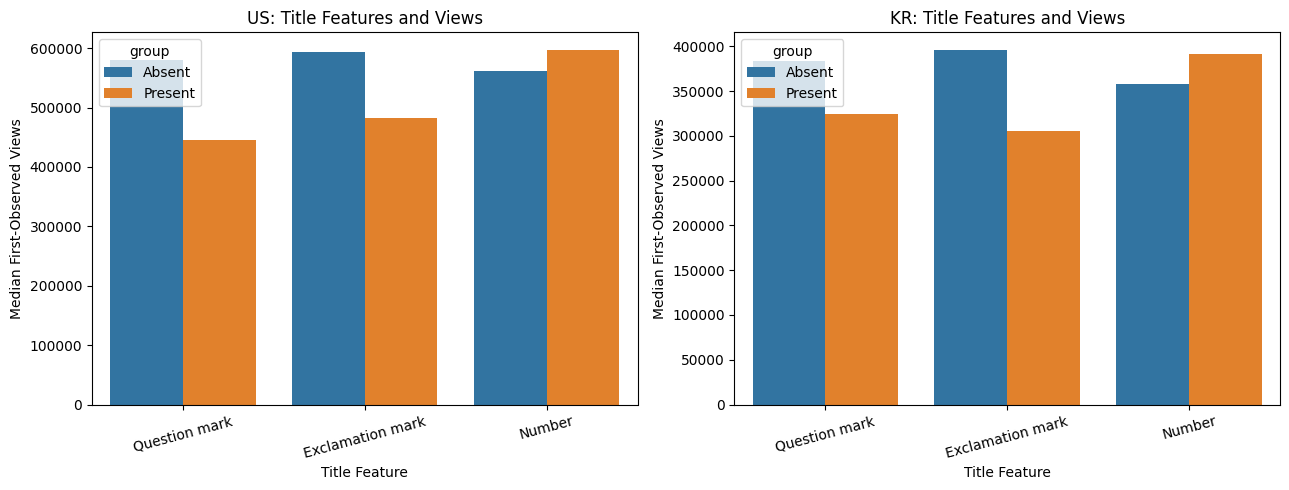

Comparison with sample sizes:


,country,pattern_label,group,videos,median_views
8,KR,Exclamation mark,Absent,17380,395696.0
9,KR,Exclamation mark,Present,4676,305844.0
10,KR,Number,Absent,11273,358359.0
11,KR,Number,Present,10783,390746.0
6,KR,Question mark,Absent,18348,383222.0
7,KR,Question mark,Present,3708,324862.0
2,US,Exclamation mark,Absent,32534,593834.0
3,US,Exclamation mark,Present,6319,483252.0
4,US,Number,Absent,25518,562210.0
5,US,Number,Present,13335,596803.0


In [21]:

# Transformation Revision 1:
# Compare title patterns with and without each feature.

title_labels = {
    "has_question": "Question mark",
    "has_exclamation": "Exclamation mark",
    "has_number": "Number"
}

comparison = pattern_summary.copy()
comparison["pattern_label"] = comparison["pattern"].map(
    title_labels
)
comparison["group"] = comparison["present"].map({
    False: "Absent",
    True: "Present"
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, country in zip(axes, COUNTRIES):
    subset = comparison[
        comparison["country"] == country
    ]

    sns.barplot(
        data=subset,
        x="pattern_label",
        y="median_views",
        hue="group",
        order=list(title_labels.values()),
        hue_order=["Absent", "Present"],
        ax=ax
    )

    ax.set_title(f"{country}: Title Features and Views")
    ax.set_xlabel("Title Feature")
    ax.set_ylabel("Median First-Observed Views")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

print("Comparison with sample sizes:")
display(
    comparison[
        ["country", "pattern_label", "group",
         "videos", "median_views"]
    ].sort_values(
        ["country", "pattern_label", "group"]
    ).round(0)
)



### Transformation Review - Revision 1

The initial title-pattern visualization showed only videos containing each title feature.

The revised comparison includes both the presence and absence of question marks, exclamation marks, and numbers.

Group sizes are reported alongside median first-observed view counts.

These results are descriptive associations. Differences in content categories, channels, publication timing, and audience size may also explain differences in observed views.

The findings should not be interpreted as causal effects of title formatting.


In [22]:

# Transformation Revision 2:
# Extract visual features from a small thumbnail sample.

from PIL import Image
from io import BytesIO
import requests

# 20 videos per country for an initial feasibility test.
visual_sample = (
    features.groupby("country", group_keys=False)
    .sample(n=20, random_state=RANDOM_STATE)
    .copy()
)

visual_results = []

for _, row in visual_sample.iterrows():
    video_id = row["video_id"]
    url = f"https://i.ytimg.com/vi/{video_id}/maxresdefault.jpg"

    result = {
        "country": row["country"],
        "video_id": video_id,
        "views": row["first_observed_views"],
        "accessible": False,
        "brightness": np.nan,
        "contrast": np.nan,
        "colorfulness": np.nan
    }

    try:
        response = requests.get(url, timeout=8)
        response.raise_for_status()

        with Image.open(BytesIO(response.content)) as img:
            if img.width < 320 or img.height < 180:
                continue

            rgb = np.asarray(
                img.convert("RGB").resize((160, 90)),
                dtype=np.float32
            )

        gray = rgb.mean(axis=2)

        result["brightness"] = float(gray.mean())
        result["contrast"] = float(gray.std())

        # Simple RGB color variation measure.
        result["colorfulness"] = float(
            np.std(rgb, axis=(0, 1)).mean()
        )

        result["accessible"] = True

    except (requests.RequestException, OSError, ValueError):
        pass

    visual_results.append(result)

visual_features = pd.DataFrame(visual_results)

print("Thumbnail visual feature availability:")
display(
    visual_features.groupby("country").agg(
        tested=("video_id", "size"),
        accessible=("accessible", "sum"),
        median_brightness=("brightness", "median"),
        median_contrast=("contrast", "median"),
        median_colorfulness=("colorfulness", "median")
    ).round(2)
)

print("\nValid visual feature records:")
print(visual_features["accessible"].sum())

print("\nSample extracted features:")
display(visual_features.head(10).round(2))


Thumbnail visual feature availability:


,tested,accessible,median_brightness,median_contrast,median_colorfulness
country,,,,,
KR,20,19,104.96,61.55,67.87
US,20,19,104.55,64.69,73.49



Valid visual feature records:
38

Sample extracted features:


,country,video_id,views,accessible,brightness,contrast,colorfulness
0,KR,PCZYPgprwFk,3913066,True,119.15,63.79,67.87
1,KR,RsxVYhn9D3A,255438,True,97.29,61.88,63.82
2,KR,FsBr0j85Zvg,1840394,True,132.60,92.70,94.97
3,KR,SljQYJk0Zbw,213385,True,89.71,70.54,73.92
4,KR,bZxf6zsggRM,350794,True,60.36,55.88,57.79
5,KR,sTprt6cZnyI,255147,True,143.82,47.56,59.12
6,KR,Kgb4sg-SCdY,1135193,False,NaN,NaN,NaN
7,KR,HhocRYYLVC4,286391,True,147.64,82.04,82.58
8,KR,1JHOl9CSmXk,3221795,True,71.53,51.58,61.10
9,KR,z0JraysWnNw,278949,True,85.09,52.23,61.94



### Transformation Review - Revision 2

The revised transformation tests whether thumbnail images can be converted into numerical visual features.

A reproducible sample of 20 videos per country is used to extract average brightness, grayscale contrast, and RGB color variation.

These measurements describe basic image properties, not subjective attractiveness or emotional impact.

The small sample is used to verify the feature extraction process. A larger and more representative sample will be needed before drawing conclusions about thumbnail characteristics and view counts.

More complex features, such as facial expressions, thumbnail text, and storytelling, require separate analysis.



## 4. Data Mining

### Objective

The Data Mining phase investigates relationships between video characteristics and first-observed Trending view counts.

The analysis includes:

1. Comparing popularity across countries and content categories.
2. Examining title and metadata features.
3. Comparing simple machine learning models.
4. Expanding thumbnail analysis and exploring actual video content.

The target is the log-transformed view count on the first observed Trending day.

This is not a prediction of final lifetime views. Different videos may have been observed at different times after publication, and the dataset includes only videos already recorded in Trending.

These limitations will be considered when interpreting the results.


Major categories and observed views:


,country,category_name,videos,median_views
3,KR,Entertainment,7662,392488.0
9,KR,People & Blogs,3568,309350.0
7,KR,Music,2605,511758.0
12,KR,Sports,1889,412059.0
1,KR,Comedy,1292,548090.0
8,KR,News & Politics,937,740440.0
20,US,Gaming,8342,533401.0
18,US,Entertainment,7606,636262.0
22,US,Music,5767,653278.0
28,US,Sports,4918,657826.0


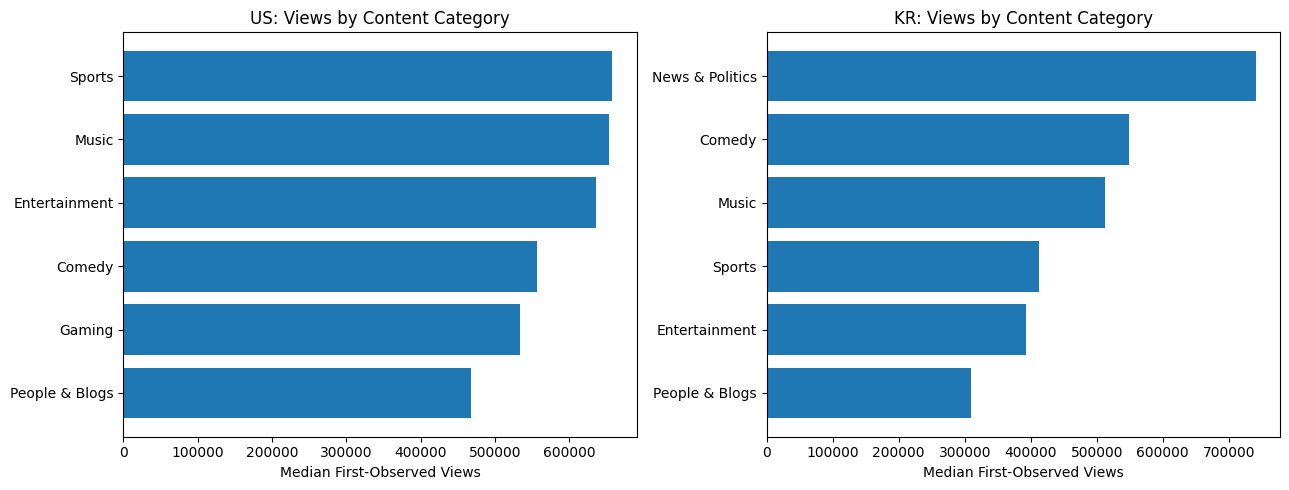

In [23]:

# Data Mining: compare category-level popularity

category_stats = (
    features.groupby(["country", "category_name"])
    .agg(
        videos=("video_id", "size"),
        median_views=("first_observed_views", "median")
    )
    .reset_index()
)

# Keep categories with enough records for comparison.
category_stats = category_stats[
    category_stats["videos"] >= 100
].copy()

top_categories = (
    category_stats.sort_values(
        ["country", "videos"],
        ascending=[True, False]
    )
    .groupby("country")
    .head(6)
)

print("Major categories and observed views:")
display(top_categories.round(0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, country in zip(axes, COUNTRIES):
    subset = top_categories[
        top_categories["country"] == country
    ].sort_values("median_views")

    ax.barh(
        subset["category_name"],
        subset["median_views"]
    )

    ax.set_title(f"{country}: Views by Content Category")
    ax.set_xlabel("Median First-Observed Views")

plt.tight_layout()
plt.show()


In [24]:

# Data Mining: prepare pre-publication metadata features

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_cols = [
    "title_length",
    "title_word_count",
    "has_question",
    "has_exclamation",
    "has_number",
    "hashtag_count",
    "tag_count",
    "publish_hour_utc"
]

categorical_cols = [
    "country",
    "category_name",
    "publish_weekday_utc"
]

model_columns = numeric_cols + categorical_cols

model_data = features.sort_values(
    ["published_at", "country", "video_id"]
).copy()

X = model_data[model_columns]
y = model_data["log_first_observed_views"]

# Chronological split based on publication dates.
# Keep entire publication dates on one side.
cutoff_date = model_data["published_at"].dt.date.quantile(0.8)

train_mask = model_data["published_at"].dt.date < cutoff_date
test_mask = ~train_mask

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", OneHotEncoder(
        handle_unknown="ignore"
    ), categorical_cols)
])

print("Train records:", len(X_train))
print("Test records:", len(X_test))
print("Cutoff date:", cutoff_date)

print("Latest training publication:",
      model_data.loc[train_mask, "published_at"].max())

print("Earliest test publication:",
      model_data.loc[test_mask, "published_at"].min())

print("Selected features:", len(model_columns))


Train records: 48681
Test records: 12228
Cutoff date: 2023-04-28
Latest training publication: 2023-04-27 23:00:14+00:00
Earliest test publication: 2023-04-28 00:00:09+00:00
Selected features: 11


In [25]:

# Data Mining: compare simple regression models

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

models = {
    "Mean Baseline": DummyRegressor(
        strategy="mean"
    ),
    "Ridge Regression": Ridge(
        alpha=10.0
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=80,
        max_depth=12,
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

results = []
fitted_models = {}

for name, estimator in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE (log views)": mean_absolute_error(
            y_test, predictions
        ),
        "RMSE (log views)": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions)
    })

    fitted_models[name] = pipeline

model_results = pd.DataFrame(results)

print("Chronological test results:")
display(
    model_results.sort_values(
        "MAE (log views)"
    ).round(4)
)


Chronological test results:


,Model,MAE (log views),RMSE (log views),R2
2,Random Forest,0.7198,0.9423,0.2086
1,Ridge Regression,0.7759,1.0069,0.0964
0,Mean Baseline,0.8140,1.0594,-0.0004


In [26]:

# Data Mining: validate the initial modeling setup

train_dates = set(
    model_data.loc[train_mask, "published_at"].dt.date
)
test_dates = set(
    model_data.loc[test_mask, "published_at"].dt.date
)

checks = {
    "Training records exist": len(X_train) > 0,
    "Test records exist": len(X_test) > 0,
    "No shared publication dates": (
        len(train_dates & test_dates) == 0
    ),
    "Chronological separation": (
        max(train_dates) < min(test_dates)
    ),
    "No outcome columns in predictors": not any(
        c in model_columns for c in [
            "view_count", "first_observed_views",
            "likes", "comment_count",
            "days_to_first_observed_trending",
            "log_first_observed_views"
        ]
    ),
    "Finite targets": (
        np.isfinite(y_train).all()
        and np.isfinite(y_test).all()
    )
}

print("Data Mining checks:")
for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")


Data Mining checks:
Training records exist: PASS
Test records exist: PASS
No shared publication dates: PASS
Chronological separation: PASS
No outcome columns in predictors: PASS
Finite targets: PASS



### Data Mining - Initial Findings

The initial analysis compares first-observed Trending view counts across major content categories in the United States and South Korea.

Three regression approaches are evaluated: a mean baseline, Ridge Regression, and Random Forest.

The models use title, category, tag, country, and publication-time features. View counts, likes, comments, and time to Trending are excluded from the predictors.

The data is split chronologically using publication dates.

The initial model results will be examined before selecting a final approach.

A larger thumbnail sample and an actual video-content analysis will be incorporated into the subsequent review and revision process.

Because only Trending videos are included and the observation times vary, the results cannot establish the causes of video popularity or predict lifetime views reliably.


In [27]:

# Data Mining Revision 1:
# Check whether training outcomes were observed
# after the chronological publication cutoff.

cutoff_timestamp = pd.Timestamp(
    cutoff_date, tz="UTC"
)

train_records = model_data.loc[train_mask].copy()
test_records = model_data.loc[test_mask].copy()

train_crossing = (
    train_records["trending_at"] >= cutoff_timestamp
)

print("Publication cutoff:", cutoff_date)

print("\nTraining videos:", len(train_records))
print(
    "Training outcomes observed on or after cutoff:",
    int(train_crossing.sum())
)
print(
    "Percentage of training outcomes crossing cutoff:",
    round(train_crossing.mean() * 100, 2)
)

print("\nLatest training Trending date:",
      train_records["trending_at"].max())

print("Earliest test Trending date:",
      test_records["trending_at"].min())

print("\nFirst-observed Trending delay distribution:")
display(
    model_data.groupby("country")[
        "calendar_days_to_trending"
    ].describe(percentiles=[0.5, 0.9, 0.99]).round(2)
)

print("\nExamples crossing the cutoff:")
display(
    train_records.loc[
        train_crossing,
        [
            "country", "title", "published_at",
            "trending_at", "first_observed_views"
        ]
    ].head(5)
)


Publication cutoff: 2023-04-28

Training videos: 48681
Training outcomes observed on or after cutoff: 88
Percentage of training outcomes crossing cutoff: 0.18

Latest training Trending date: 2023-05-02 00:00:00+00:00
Earliest test Trending date: 2023-04-29 00:00:00+00:00

First-observed Trending delay distribution:


,count,mean,std,min,50%,90%,99%,max
country,,,,,,,,
KR,22056.0,1.35,0.97,0.0,1.0,2.0,5.0,27.0
US,38853.0,1.51,0.79,0.0,1.0,2.0,4.0,28.0



Examples crossing the cutoff:


,country,title,published_at,trending_at,first_observed_views
1028,KR,"수단 군부 무력 충돌, 사상자 4천 명 육박 (KBS_306회_2023.04.22.방송)",2023-04-24 01:00:09+00:00,2023-04-29 00:00:00+00:00,573640
14280,KR,[와글와글] 전기차로 위장해 충전기까지 누리꾼 경악 (2023.04.25/뉴스투데이...,2023-04-24 22:44:42+00:00,2023-04-28 00:00:00+00:00,2297633
16790,KR,"(종합) 공군, 수단 교민 구출 작전(프라미스) 출발 및 임무수행 영상",2023-04-25 09:59:25+00:00,2023-04-29 00:00:00+00:00,173055
6440,KR,재수생의 하루,2023-04-25 13:43:33+00:00,2023-04-29 00:00:00+00:00,893406
51516,US,The NFC Smack Talk Heats the Ice Tubs With Kev...,2023-04-25 15:04:58+00:00,2023-04-28 00:00:00+00:00,1645612



### Data Mining Review - Revision 1

The initial models were evaluated using a chronological split based on publication dates.

However, the prediction target was measured on the first observed Trending date, which may be later than the publication date.

The revised diagnostic checks whether any training outcomes were observed on or after the test-period cutoff.

This distinction matters because separating publication dates does not necessarily separate the observation times of the target values.

The evaluation design will be adjusted based on the diagnostic results. The initial model scores are treated as preliminary.


In [28]:

# Data Mining Revision 2:
# Exclude training outcomes observed on or after the cutoff.

from sklearn.base import clone

safe_train_mask = (
    train_mask
    & (model_data["trending_at"] < cutoff_timestamp)
)

X_train_safe = X.loc[safe_train_mask]
y_train_safe = y.loc[safe_train_mask]

print("Original training records:", len(X_train))
print("Revised training records:", len(X_train_safe))
print("Excluded records:", len(X_train) - len(X_train_safe))
print("Test records:", len(X_test))

# Re-evaluate all models using the revised training set.
revised_results = []
revised_models = {}

for name, estimator in models.items():

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(estimator))
    ])

    pipeline.fit(X_train_safe, y_train_safe)
    predictions = pipeline.predict(X_test)

    revised_results.append({
        "Model": name,
        "MAE (log views)": mean_absolute_error(
            y_test, predictions
        ),
        "RMSE (log views)": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions)
    })

    revised_models[name] = pipeline

revised_model_results = pd.DataFrame(
    revised_results
).sort_values("MAE (log views)")

print("\nRevised chronological test results:")
display(revised_model_results.round(4))

# Validate observation-time separation.
latest_train_observation = model_data.loc[
    safe_train_mask, "trending_at"
].max()

earliest_test_observation = model_data.loc[
    test_mask, "trending_at"
].min()

checks = {
    "No future training outcomes": (
        latest_train_observation < cutoff_timestamp
    ),
    "Training/test observations separated": (
        latest_train_observation < earliest_test_observation
    ),
    "Test set unchanged": (
        len(X_test) == 12228
    ),
    "Finite revised targets": np.isfinite(
        y_train_safe
    ).all()
}

print("\nRevised evaluation checks:")
for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nLatest training observation:",
      latest_train_observation)

print("Earliest test observation:",
      earliest_test_observation)


Original training records: 48681
Revised training records: 48593
Excluded records: 88
Test records: 12228

Revised chronological test results:


,Model,MAE (log views),RMSE (log views),R2
2,Random Forest,0.7200,0.9427,0.2079
1,Ridge Regression,0.7759,1.0069,0.0963
0,Mean Baseline,0.8140,1.0594,-0.0004



Revised evaluation checks:
No future training outcomes: PASS
Training/test observations separated: PASS
Test set unchanged: PASS
Finite revised targets: PASS

Latest training observation: 2023-04-27 00:00:00+00:00
Earliest test observation: 2023-04-29 00:00:00+00:00



### Data Mining Review - Revision 2

The diagnostic identified 88 training videos whose target view counts were observed on or after the publication cutoff.

The revised evaluation excludes these records from training while retaining the original held-out test set.

All three models are trained again using the revised training data.

The updated checks verify that training target observations occur before the cutoff and before the test target observations.

The original model results are retained for comparison, but the revised evaluation will be used for the final analysis.

This correction improves chronological separation. It does not resolve other limitations, including differences in the time between publication and first observed Trending appearance.


In [29]:

# Data Mining: select a pilot sample for actual video analysis

# Select 10 videos per country:
# 5 from the lower half and 5 from the upper half
# of observed view counts within each country.

pilot_parts = []

for country in COUNTRIES:
    subset = features[
        features["country"] == country
    ].copy()

    median_views = subset["first_observed_views"].median()

    lower = subset[
        subset["first_observed_views"] <= median_views
    ].sample(n=5, random_state=RANDOM_STATE)

    upper = subset[
        subset["first_observed_views"] > median_views
    ].sample(n=5, random_state=RANDOM_STATE)

    pilot_parts.extend([lower, upper])

video_pilot = pd.concat(
    pilot_parts, ignore_index=True
)

video_pilot["youtube_url"] = (
    "https://www.youtube.com/watch?v="
    + video_pilot["video_id"].astype(str)
)

pilot_columns = [
    "country",
    "video_id",
    "title",
    "category_name",
    "published_at",
    "first_observed_views",
    "youtube_url"
]

print("Video content pilot sample:")
display(video_pilot[pilot_columns])

print("\nSelected videos by country:")
display(video_pilot["country"].value_counts())

print("\nUnique videos:",
      video_pilot["video_id"].nunique())


Video content pilot sample:


,country,video_id,title,category_name,published_at,first_observed_views,youtube_url
0,US,9KswwVlpBsM,Corrupted Sonic Boom VS Shaggy & BF & Toon Squ...,People & Blogs,2022-05-14 11:00:15+00:00,562731,https://www.youtube.com/watch?v=9KswwVlpBsM
1,US,9trjxvaWP_0,Starfield: The Settled Systems - Where Hope is...,Gaming,2023-07-25 14:01:36+00:00,101031,https://www.youtube.com/watch?v=9trjxvaWP_0
2,US,qQoM4esIvnc,"Minecraft Manhunt, But We're Stuck Together...",Gaming,2023-12-10 18:00:31+00:00,261708,https://www.youtube.com/watch?v=qQoM4esIvnc
3,US,EHww_EWlJ-A,What if LeBron and Kobe Played Together?,Gaming,2023-11-19 14:00:20+00:00,164375,https://www.youtube.com/watch?v=EHww_EWlJ-A
4,US,uIPxKLCOX6c,I Tested OTHER Art Youtuber's Art Products...,Entertainment,2023-02-10 15:00:40+00:00,153567,https://www.youtube.com/watch?v=uIPxKLCOX6c
5,US,9amJuvb3grU,AI learns to WALK 3D (Part 2),Education,2022-12-21 12:01:41+00:00,728145,https://www.youtube.com/watch?v=9amJuvb3grU
6,US,A2aSmJ-SXCo,Post Malone Has His Brain Hacked By Spicy Wing...,Entertainment,2022-05-26 15:00:08+00:00,1589986,https://www.youtube.com/watch?v=A2aSmJ-SXCo
7,US,qTtxoz3OIlU,RESPECT | Official Trailer | MGM Studios,Entertainment,2021-05-19 12:45:04+00:00,1113059,https://www.youtube.com/watch?v=qTtxoz3OIlU
8,US,EPzl0qJl_6s,Don’t Want To Pay Taxes? Law By Mike #Shorts #...,Education,2021-10-31 07:49:18+00:00,1029811,https://www.youtube.com/watch?v=EPzl0qJl_6s
9,US,uQSokD4kD4Q,"Court Cam: Man SPITS on Judge, Then Starts Jai...",Entertainment,2021-05-07 17:00:33+00:00,778392,https://www.youtube.com/watch?v=uQSokD4kD4Q



Selected videos by country:


,count
country,
US,10
KR,10



Unique videos: 20



### Video Content Pilot - Candidate Selection

A pilot sample of 20 videos is selected, with 10 from the United States and 10 from South Korea.

Within each country, five videos are sampled from each side of the median first-observed view count.

The pilot will investigate whether actual video material or transcripts are accessible for examining introductions, storytelling, topical references, and cultural trends.

Selecting videos does not mean their content has been analyzed. Accessibility and the reliability of content annotations must be checked before making findings.


In [30]:

# Data Mining: check availability of pilot videos

import requests
import time

access_results = []

for _, row in video_pilot.iterrows():
    video_id = row["video_id"]

    result = {
        "country": row["country"],
        "video_id": video_id,
        "title": row["title"],
        "metadata_accessible": False,
        "status_code": None
    }

    try:
        response = requests.get(
            "https://www.youtube.com/oembed",
            params={
                "url": f"https://www.youtube.com/watch?v={video_id}",
                "format": "json"
            },
            timeout=10
        )

        result["status_code"] = response.status_code
        result["metadata_accessible"] = response.ok

    except requests.RequestException:
        pass

    access_results.append(result)
    time.sleep(0.2)

video_access = pd.DataFrame(access_results)

print("Pilot video metadata availability:")
display(
    video_access.groupby("country").agg(
        tested=("video_id", "size"),
        accessible=("metadata_accessible", "sum")
    )
)

print("\nDetailed results:")
display(video_access)


Pilot video metadata availability:


,tested,accessible
country,,
KR,10,8
US,10,9



Detailed results:


,country,video_id,title,metadata_accessible,status_code
0,US,9KswwVlpBsM,Corrupted Sonic Boom VS Shaggy & BF & Toon Squ...,False,404
1,US,9trjxvaWP_0,Starfield: The Settled Systems - Where Hope is...,True,200
2,US,qQoM4esIvnc,"Minecraft Manhunt, But We're Stuck Together...",True,200
3,US,EHww_EWlJ-A,What if LeBron and Kobe Played Together?,True,200
4,US,uIPxKLCOX6c,I Tested OTHER Art Youtuber's Art Products...,True,200
5,US,9amJuvb3grU,AI learns to WALK 3D (Part 2),True,200
6,US,A2aSmJ-SXCo,Post Malone Has His Brain Hacked By Spicy Wing...,True,200
7,US,qTtxoz3OIlU,RESPECT | Official Trailer | MGM Studios,True,200
8,US,EPzl0qJl_6s,Don’t Want To Pay Taxes? Law By Mike #Shorts #...,True,200
9,US,uQSokD4kD4Q,"Court Cam: Man SPITS on Judge, Then Starts Jai...",True,200



### Video Accessibility Check

The 20 selected videos are checked for public YouTube embed metadata availability.

This test helps identify potential candidates for deeper content analysis.

Successful metadata access does not guarantee that the video can be played or that transcripts are available. Failed requests may also result from temporary access restrictions.

Actual content analysis will require accessible video material or transcripts, followed by a consistent annotation procedure.


In [31]:

# Data Mining: test public transcript availability

%pip -q install youtube-transcript-api

from youtube_transcript_api import YouTubeTranscriptApi
import time

ytt = YouTubeTranscriptApi()

available_pilot = video_access[
    video_access["metadata_accessible"]
].copy()

transcript_results = []
pilot_transcripts = {}

for _, row in available_pilot.iterrows():
    video_id = row["video_id"]

    result = {
        "country": row["country"],
        "video_id": video_id,
        "transcript_available": False,
        "language": None,
        "generated": None,
        "segments": 0,
        "intro_chars": 0,
        "status": None
    }

    try:
        transcript_list = ytt.list(video_id)

        # Prefer the original English or Korean transcript.
        candidates = list(transcript_list)

        preferred = [
            t for t in candidates
            if t.language_code.startswith(
                ("en", "ko")
            )
        ]

        selected = (
            preferred[0] if preferred
            else candidates[0] if candidates
            else None
        )

        if selected is None:
            result["status"] = "No transcript found"
        else:
            fetched = selected.fetch()

            segments = [
                {
                    "start": item.start,
                    "duration": item.duration,
                    "text": item.text
                }
                for item in fetched
            ]

            intro = " ".join(
                s["text"]
                for s in segments
                if s["start"] < 60
            )

            pilot_transcripts[video_id] = segments

            result.update({
                "transcript_available": True,
                "language": selected.language_code,
                "generated": selected.is_generated,
                "segments": len(segments),
                "intro_chars": len(intro),
                "status": "Success"
            })

    except Exception as e:
        result["status"] = type(e).__name__

    transcript_results.append(result)
    time.sleep(0.5)

transcript_check = pd.DataFrame(transcript_results)

print("Transcript availability by country:")
display(
    transcript_check.groupby("country").agg(
        tested=("video_id", "size"),
        available=("transcript_available", "sum"),
        median_segments=("segments", "median")
    )
)

print("\nDetailed transcript results:")
display(transcript_check)

print("\nSuccessfully retrieved transcripts:",
      len(pilot_transcripts))


Transcript availability by country:


,tested,available,median_segments
country,,,
KR,8,6,21.0
US,9,8,159.0



Detailed transcript results:


,country,video_id,transcript_available,language,generated,segments,intro_chars,status
0,US,9trjxvaWP_0,False,None,None,0,0,TranscriptsDisabled
1,US,qQoM4esIvnc,True,en,True,626,1320,Success
2,US,EHww_EWlJ-A,True,en,True,762,1051,Success
3,US,uIPxKLCOX6c,True,en,False,159,1076,Success
4,US,9amJuvb3grU,True,en,True,667,969,Success
5,US,A2aSmJ-SXCo,True,en,True,711,1012,Success
6,US,qTtxoz3OIlU,True,en,True,39,429,Success
7,US,EPzl0qJl_6s,True,en,True,9,301,Success
8,US,uQSokD4kD4Q,True,en,True,103,675,Success
9,KR,ey9mlAoUhYc,True,ko,True,81,64,Success



Successfully retrieved transcripts: 14



### Transcript Availability Pilot

The project tests whether public transcripts can be retrieved from accessible YouTube videos.

The pilot records transcript language, whether captions were automatically generated, the number of transcript segments, and the amount of text available from the first 60 seconds.

Transcript access may fail even when video metadata is publicly available.

Successful retrieval provides material for examining spoken introductions, storytelling, and topical references. However, captions do not capture all visual editing, music, humor, or audience reactions.

Transcript availability and limitations will be considered before selecting the final content-analysis sample.



### Transcript Pilot Result

Transcript retrieval was attempted for 17 videos across the United States and South Korea.

No transcripts were retrieved. Sixteen requests returned `RequestBlocked`, and one returned `VideoUnplayable`.

These failures do not establish that the videos lack captions. They indicate that the current retrieval method was unsuccessful.

The project will consider alternative access methods or a smaller manually reviewed video sample for actual content analysis.


In [32]:

# Data Mining: inspect descriptions for content analysis

content_pilot = video_pilot.copy()

content_pilot["description_text"] = (
    content_pilot["description"]
    .fillna("")
    .astype(str)
)

# Remove links for a more useful text preview.
content_pilot["description_preview"] = (
    content_pilot["description_text"]
    .str.replace(r"https?://\S+", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.slice(0, 250)
)

content_pilot["description_chars"] = (
    content_pilot["description_preview"].str.len()
)

content_pilot["has_useful_description"] = (
    content_pilot["description_chars"] >= 50
)

content_pilot = content_pilot.merge(
    video_access[
        ["country", "video_id", "metadata_accessible"]
    ],
    on=["country", "video_id"],
    how="left",
    validate="one_to_one"
)

print("Description availability in pilot sample:")
display(
    content_pilot.groupby("country").agg(
        sampled=("video_id", "size"),
        useful_descriptions=("has_useful_description", "sum"),
        accessible_metadata=("metadata_accessible", "sum")
    )
)

print("\nDescription previews:")
display(
    content_pilot[
        [
            "country",
            "video_id",
            "title",
            "description_chars",
            "description_preview"
        ]
    ].to_string(index=False, max_colwidth=100)
)


Description availability in pilot sample:


,sampled,useful_descriptions,accessible_metadata
country,,,
KR,10,9,8
US,10,10,9



Description previews:


"country    video_id                                                                                                title  description_chars                                                                                  description_preview\n     US 9KswwVlpBsM     Corrupted Sonic Boom VS Shaggy & BF & Toon Squad (Ep. 7) | Come Learn With Pibby x FNF Animation                250 Corrupted Sonic Boom VS Shaggy, BF, Pibby, Pico, Robin, Finn & Jake (Ep. 7) | Come Learn With Pib...\n     US 9trjxvaWP_0                                                 Starfield: The Settled Systems - Where Hope is Built                250 Vanna—an Akila City orphan of the famous Colony Wars—desperately wants to explore the stars and o...\n     US qQoM4esIvnc                                                       Minecraft Manhunt, But We're Stuck Together...                250 Download Honkai Impact 3rd using our link and start playing now! Minecraft Manhunt, But We're Stu...\n     US EHww_EWlJ-A            


### Content Description Pilot

Because automated transcript retrieval was blocked, the analysis examines available video descriptions as an alternative source of contextual information.

The pilot checks whether descriptions contain enough text for exploratory topic analysis after removing URLs.

Descriptions may include promotional text, links, credits, or hashtags rather than descriptions of the video itself.

They are not substitutes for actual transcripts or direct video observation. Additionally, the stored descriptions may have been updated after the first Trending observation.

Any findings based on descriptions will therefore be labeled as metadata-based topic analysis, not direct analysis of spoken or visual content.


Top keywords by country:


,country,keyword,frequency
0,US,to,10
1,US,in,8
2,US,her,6
3,US,by,6
4,US,is,5
5,US,of,4
6,US,but,4
7,US,on,4
8,US,vs,3
9,US,shaggy,3


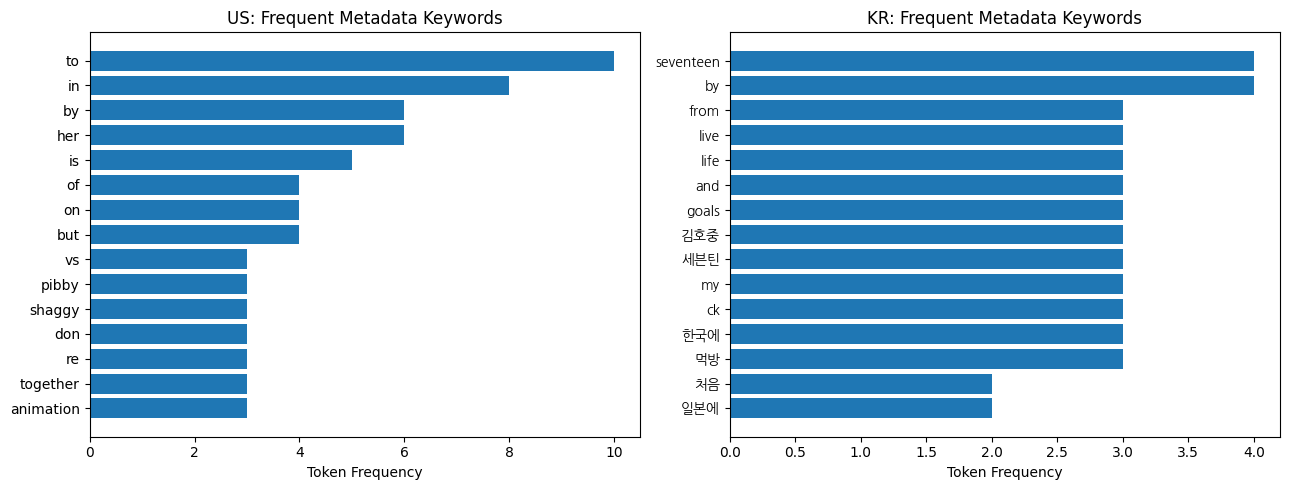

In [33]:

# Data Mining: exploratory topic keywords from titles and descriptions

import re
from collections import Counter

stopwords = {
    "US": {
        "the", "and", "for", "you", "your", "with",
        "this", "that", "from", "are", "have",
        "was", "will", "our", "all", "not",
        "video", "subscribe", "channel", "watch"
    },
    "KR": {
        "그리고", "하지만", "오늘", "영상", "구독",
        "좋아요", "감사합니다", "여러분", "채널",
        "에서", "으로", "합니다", "있는"
    }
}

keyword_rows = []

for country in COUNTRIES:
    subset = content_pilot[
        content_pilot["country"] == country
    ]

    tokens = []

    for _, row in subset.iterrows():
        text = (
            str(row["title"]) + " "
            + str(row["description_preview"])
        ).lower()

        words = re.findall(
            r"[a-zA-Z가-힣]{2,}",
            text
        )

        words = [
            w for w in words
            if w not in stopwords[country]
        ]

        tokens.extend(words)

    counts = Counter(tokens)

    for word, count in counts.most_common(15):
        keyword_rows.append({
            "country": country,
            "keyword": word,
            "frequency": count
        })

keyword_summary = pd.DataFrame(keyword_rows)

print("Top keywords by country:")
display(keyword_summary)

# Ensure Korean characters display correctly in Colab plots.
from matplotlib import font_manager
import subprocess

nanum_paths = list(Path("/usr/share/fonts").rglob("NanumGothic.ttf"))
if not nanum_paths:
    subprocess.run(
        ["apt-get", "-qq", "update"],
        check=True, capture_output=True, text=True
    )
    subprocess.run(
        ["apt-get", "-qq", "install", "-y", "fonts-nanum"],
        check=True, capture_output=True, text=True
    )
    nanum_paths = list(Path("/usr/share/fonts").rglob("NanumGothic.ttf"))

if not nanum_paths:
    raise RuntimeError("Korean font NanumGothic was not found")

font_manager.fontManager.addfont(str(nanum_paths[0]))
korean_font = font_manager.FontProperties(fname=str(nanum_paths[0]))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, country in zip(axes, COUNTRIES):
    subset = keyword_summary[
        keyword_summary["country"] == country
    ].sort_values("frequency")

    ax.barh(
        subset["keyword"],
        subset["frequency"]
    )
    if country == "KR":
        for tick_label in ax.get_yticklabels():
            tick_label.set_fontproperties(korean_font)

    ax.set_title(f"{country}: Frequent Metadata Keywords")
    ax.set_xlabel("Token Frequency")

plt.tight_layout()
plt.show()



### Metadata Topic Exploration

The pilot explores frequently occurring words in video titles and description previews for the United States and South Korea.

Basic tokenization and language-specific stopword lists are applied separately to each country.

This is an exploratory metadata analysis. Frequent words do not necessarily identify cultural trends, and the small sample cannot represent all Trending videos.

Korean word segmentation is simplified, and descriptions may include promotional language.

The next analysis will distinguish descriptive keywords from more meaningful cultural or topical references.


Topic labels for the 20 pilot videos:


,country,video_id,title,topics,topic_count
0,US,9KswwVlpBsM,Corrupted Sonic Boom VS Shaggy & BF & Toon Squ...,Gaming,1
1,US,9trjxvaWP_0,Starfield: The Settled Systems - Where Hope is...,Gaming,1
2,US,qQoM4esIvnc,"Minecraft Manhunt, But We're Stuck Together...","Gaming, Music / K-pop",2
3,US,EHww_EWlJ-A,What if LeBron and Kobe Played Together?,Sports,1
4,US,uIPxKLCOX6c,I Tested OTHER Art Youtuber's Art Products...,Unclassified,0
5,US,9amJuvb3grU,AI learns to WALK 3D (Part 2),"Music / K-pop, Technology / AI",2
6,US,A2aSmJ-SXCo,Post Malone Has His Brain Hacked By Spicy Wing...,"Music / K-pop, Food",2
7,US,qTtxoz3OIlU,RESPECT | Official Trailer | MGM Studios,Film / TV,1
8,US,EPzl0qJl_6s,Don’t Want To Pay Taxes? Law By Mike #Shorts #...,"Humor / Shorts, News / Politics",2
9,US,uQSokD4kD4Q,"Court Cam: Man SPITS on Judge, Then Starts Jai...","Lifestyle, Film / TV",2



Metadata topic counts by country:


country,KR,US
topic,,
Film / TV,2,2
Food,1,1
Gaming,0,3
Humor / Shorts,1,1
Lifestyle,2,1
Music / K-pop,5,3
News / Politics,0,1
Sports,1,1
Technology / AI,0,1


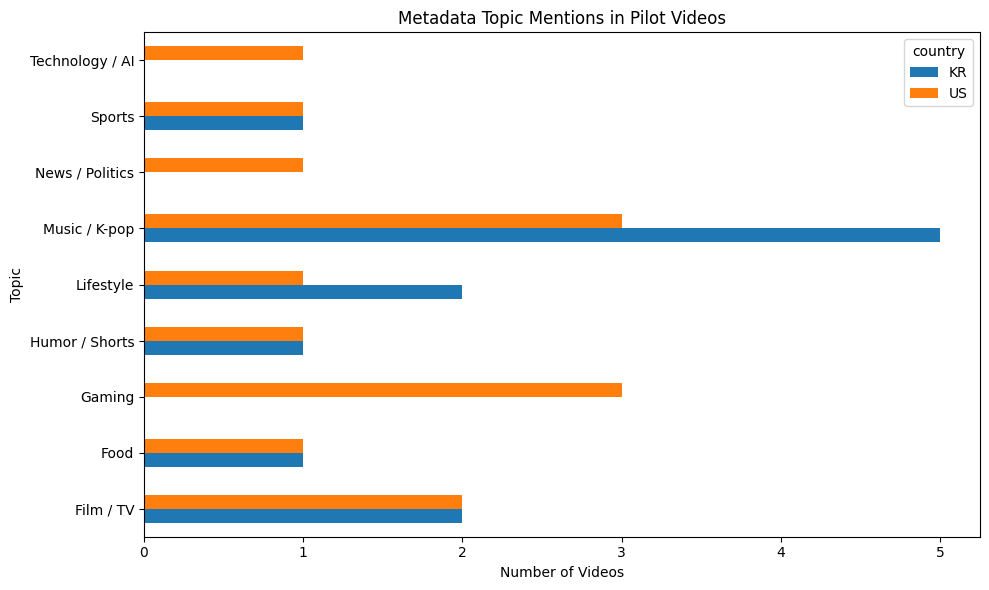

In [34]:

# Data Mining: classify exploratory metadata topics

import re

topic_patterns = {
    "Gaming": r"game|gaming|minecraft|roblox|sonic|starfield|게임|마인크래프트|플레이",
    "Music / K-pop": r"music|song|sing|concert|band|kpop|k-pop|seventeen|ive|노래|음악|가수|세븐틴|아이브|김호중",
    "Sports": r"sports|football|soccer|nba|lebron|kobe|spurs|man utd|goal|축구|야구|농구|경기",
    "Food": r"food|eating|mukbang|ramen|spicy wing|먹방|라면|음식|요리",
    "Lifestyle": r"vlog|travel|family|relationship|date|trip|여행|브이로그|가족|일상|연애",
    "Film / TV": r"movie|film|trailer|series|episode|drama|영화|드라마|방송|예고편|스우파",
    "Technology / AI": r"artificial intelligence|machine learning|ai learns|technology|robot|인공지능|로봇|기술",
    "Humor / Shorts": r"funny|comedy|prank|meme|shorts|joke|웃긴|개그|몰카|반전",
    "News / Politics": r"news|politics|election|government|law|taxes|뉴스|정치|정부|법률|선거"
}

topic_records = []

for _, row in content_pilot.iterrows():
    text = (
        str(row["title"]) + " "
        + str(row["description_preview"])
    ).lower()

    matches = [
        topic
        for topic, pattern in topic_patterns.items()
        if re.search(pattern, text, flags=re.IGNORECASE)
    ]

    topic_records.append({
        "country": row["country"],
        "video_id": row["video_id"],
        "title": row["title"],
        "topics": ", ".join(matches) if matches else "Unclassified",
        "topic_count": len(matches)
    })

topic_pilot = pd.DataFrame(topic_records)

print("Topic labels for the 20 pilot videos:")
display(topic_pilot)

# A video can belong to multiple topics.
topic_counts = []

for country in COUNTRIES:
    subset = topic_pilot[topic_pilot["country"] == country]

    for topic in topic_patterns:
        count = subset["topics"].apply(
            lambda x: topic in x.split(", ")
        ).sum()

        topic_counts.append({
            "country": country,
            "topic": topic,
            "videos": int(count)
        })

topic_summary = pd.DataFrame(topic_counts)

print("\nMetadata topic counts by country:")
display(
    topic_summary.pivot(
        index="topic",
        columns="country",
        values="videos"
    ).fillna(0).astype(int)
)

# English topic labels avoid Korean font rendering errors.
plot_data = topic_summary.pivot(
    index="topic",
    columns="country",
    values="videos"
).fillna(0)

plot_data.plot(
    kind="barh",
    figsize=(10, 6),
    title="Metadata Topic Mentions in Pilot Videos"
)

plt.xlabel("Number of Videos")
plt.ylabel("Topic")
plt.tight_layout()
plt.show()



### Metadata Topic Classification

The initial keyword-frequency analysis was dominated by common words and included Korean font-rendering issues.

The revised analysis uses predefined English and Korean keyword patterns to identify broad content topics in video titles and description previews.

Each video may receive multiple topic labels, including Gaming, Music, Sports, Food, Lifestyle, and Technology.

These labels are exploratory and depend on the chosen keywords. They are not independently validated classifications of the videos' actual content.

The pilot sample contains only 10 videos per country, so the topic counts should not be generalized to all Trending videos or interpreted as evidence of national cultural preferences.


In [35]:

# Data Mining: refine topic classification using video titles

import re
import unicodedata

refined_patterns = {
    "Gaming": [
        r"\b(?:game|gaming|minecraft|roblox|sonic|starfield)\b",
        r"게임|마인크래프트|플레이"
    ],
    "Music / K-pop": [
        r"\b(?:music|song|concert|k-pop|kpop|seventeen|ive|singer)\b",
        r"\bband\s+live\b",
        r"노래|음악|가수|세븐틴|아이브|김호중"
    ],
    "Sports": [
        r"\b(?:football|soccer|nba|lebron|kobe|spurs|man utd|highlights)\b",
        r"축구|야구|농구|스포츠|경기"
    ],
    "Food": [
        r"\b(?:food|mukbang|ramen|eating|spicy wings?)\b",
        r"먹방|라면|음식|요리"
    ],
    "Lifestyle": [
        r"\b(?:vlog|travel|family|relationship|trip)\b",
        r"여행|브이로그|가족|일상|연애|재회"
    ],
    "Film / TV": [
        r"\b(?:movie|film|trailer|drama|episode|court cam)\b",
        r"영화|드라마|방송|예고편|스우파|불후의 명곡"
    ],
    "Technology / AI": [
        r"\b(?:artificial intelligence|machine learning|ai learns|robot|technology)\b",
        r"인공지능|로봇|기술"
    ],
    "Humor / Shorts": [
        r"\b(?:comedy|prank|meme|shorts|funny)\b",
        r"개그|몰카|반전|웃긴"
    ],
    "News / Politics": [
        r"\b(?:news|politics|election|government|taxes)\b",
        r"뉴스|정치|정부|선거"
    ]
}

refined_records = []

for _, row in content_pilot.iterrows():
    title = unicodedata.normalize(
        "NFC", str(row["title"])
    ).lower()

    matched = [
        topic
        for topic, patterns in refined_patterns.items()
        if any(re.search(p, title) for p in patterns)
    ]

    refined_records.append({
        "country": row["country"],
        "video_id": row["video_id"],
        "title": row["title"],
        "topics": ", ".join(matched) if matched else "Unclassified",
        "topic_count": len(matched)
    })

refined_topic_pilot = pd.DataFrame(refined_records)

print("Refined title-based topic labels:")
display(refined_topic_pilot)

refined_counts = []

for country in COUNTRIES:
    subset = refined_topic_pilot[
        refined_topic_pilot["country"] == country
    ]

    for topic in refined_patterns:
        refined_counts.append({
            "country": country,
            "topic": topic,
            "videos": int(
                subset["topics"].apply(
                    lambda x: topic in x.split(", ")
                ).sum()
            )
        })

refined_topic_summary = pd.DataFrame(refined_counts)

print("\nRefined topic counts:")
display(
    refined_topic_summary.pivot(
        index="topic", columns="country", values="videos"
    ).fillna(0).astype(int)
)

print("\nUnclassified videos:")
display(
    refined_topic_pilot[
        refined_topic_pilot["topic_count"] == 0
    ][["country", "title"]]
)


Refined title-based topic labels:


,country,video_id,title,topics,topic_count
0,US,9KswwVlpBsM,Corrupted Sonic Boom VS Shaggy & BF & Toon Squ...,Gaming,1
1,US,9trjxvaWP_0,Starfield: The Settled Systems - Where Hope is...,Gaming,1
2,US,qQoM4esIvnc,"Minecraft Manhunt, But We're Stuck Together...",Gaming,1
3,US,EHww_EWlJ-A,What if LeBron and Kobe Played Together?,Sports,1
4,US,uIPxKLCOX6c,I Tested OTHER Art Youtuber's Art Products...,Unclassified,0
5,US,9amJuvb3grU,AI learns to WALK 3D (Part 2),Technology / AI,1
6,US,A2aSmJ-SXCo,Post Malone Has His Brain Hacked By Spicy Wing...,Food,1
7,US,qTtxoz3OIlU,RESPECT | Official Trailer | MGM Studios,Film / TV,1
8,US,EPzl0qJl_6s,Don’t Want To Pay Taxes? Law By Mike #Shorts #...,"Humor / Shorts, News / Politics",2
9,US,uQSokD4kD4Q,"Court Cam: Man SPITS on Judge, Then Starts Jai...",Film / TV,1



Refined topic counts:


country,KR,US
topic,,
Film / TV,2,2
Food,1,1
Gaming,0,3
Humor / Shorts,1,1
Lifestyle,2,0
Music / K-pop,3,0
News / Politics,0,1
Sports,1,1
Technology / AI,0,1



Unclassified videos:


,country,title
4,US,I Tested OTHER Art Youtuber's Art Products...
10,KR,일본에 사시는 장모님께서 딸이 어떻게 사는지 궁금하여 한국에 오셨습니다 (한국 회 ...



### Topic Classification Refinement

The initial topic classification produced false positives because short keyword patterns matched parts of unrelated words.

The refined method uses video titles, more specific keyword patterns, and word boundaries for English terms.

This reduces matches caused by promotional descriptions and unrelated substrings.

The labels remain rule-based and exploratory. Some videos may be unclassified, and titles alone cannot reliably identify all topics, cultural references, or elements of the actual video content.

These results describe the selected pilot sample rather than the full Trending video population.


In [36]:

# Data Mining: expand thumbnail feature analysis

import requests
import numpy as np
import pandas as pd
from PIL import Image
from io import BytesIO
import time

thumbnail_samples = []

for country in COUNTRIES:
    subset = features[
        features["country"] == country
    ].copy()

    median_views = subset["first_observed_views"].median()

    for group, mask in [
        ("Lower half", subset["first_observed_views"] <= median_views),
        ("Upper half", subset["first_observed_views"] > median_views)
    ]:
        selected = subset.loc[mask].sample(
            n=50,
            random_state=RANDOM_STATE
        ).copy()

        selected["view_group"] = group
        thumbnail_samples.append(selected)

thumbnail_sample = pd.concat(
    thumbnail_samples,
    ignore_index=True
)

thumbnail_records = []
session = requests.Session()

for _, row in thumbnail_sample.iterrows():
    video_id = row["video_id"]

    record = {
        "country": row["country"],
        "video_id": video_id,
        "view_group": row["view_group"],
        "first_observed_views": row["first_observed_views"],
        "accessible": False,
        "brightness": np.nan,
        "contrast": np.nan,
        "colorfulness": np.nan
    }

    url = (
        f"https://i.ytimg.com/vi/{video_id}/maxresdefault.jpg"
    )

    try:
        response = session.get(url, timeout=8)
        response.raise_for_status()

        image = Image.open(
            BytesIO(response.content)
        ).convert("RGB")

        if image.width >= 320 and image.height >= 180:
            pixels = np.asarray(
                image.resize((160, 90)),
                dtype=np.float32
            )

            gray = pixels.mean(axis=2)

            record.update({
                "accessible": True,
                "brightness": float(gray.mean()),
                "contrast": float(gray.std()),
                "colorfulness": float(
                    pixels.std(axis=(0, 1)).mean()
                )
            })

    except (requests.RequestException, OSError, ValueError):
        pass

    thumbnail_records.append(record)
    time.sleep(0.1)

thumbnail_expanded = pd.DataFrame(thumbnail_records)

print("Expanded thumbnail availability:")
display(
    thumbnail_expanded.groupby(
        ["country", "view_group"]
    ).agg(
        tested=("video_id", "size"),
        accessible=("accessible", "sum")
    )
)

print("\nTotal valid thumbnails:",
      int(thumbnail_expanded["accessible"].sum()))

print("\nVisual feature summary:")
display(
    thumbnail_expanded[
        thumbnail_expanded["accessible"]
    ].groupby("country")[
        ["brightness", "contrast", "colorfulness"]
    ].agg(["median", "std"]).round(2)
)

session.close()


Expanded thumbnail availability:


tested  accessible
country view_group                    
KR      Lower half      50          46
        Upper half      50          43
US      Lower half      50          44
        Upper half      50          46


Total valid thumbnails: 179

Visual feature summary:


brightness        contrast        colorfulness       
            median    std   median    std       median    std
country                                                      
KR          109.86  35.74    60.44  12.48        64.80  12.75
US          101.85  39.04    58.69  14.19        65.24  15.33


### Expanded Thumbnail Analysis

The thumbnail pilot is expanded to 200 randomly selected videos, with 100 from the United States and 100 from South Korea.

Within each country, 50 videos are sampled from each side of the median first-observed view count.

For accessible high-resolution thumbnails, three numerical visual features are extracted: brightness, contrast, and a simple color-variation measure.

The sampling design supports exploratory comparisons between higher- and lower-view groups within Trending videos.

These image statistics do not directly measure attractiveness, click-through rate, emotional expression, or thumbnail text quality.

Any associations with views will be examined in the next step, without treating them as causal effects.


Visual features by view group:


videos  median_views  brightness  contrast  colorfulness
country view_group                                                          
KR      Lower half      46      221970.5      110.47     57.35         62.79
        Upper half      43     1043072.0      109.86     64.39         69.68
US      Lower half      44      302673.5      100.96     61.25         66.84
        Upper half      46      993907.5      104.00     56.46         63.24


Spearman correlations with log views:


,country,feature,spearman_rho,sample_size
0,US,brightness,0.0383,90
1,US,contrast,0.0746,90
2,US,colorfulness,0.0293,90
3,KR,brightness,0.0180,89
4,KR,contrast,0.0459,89
5,KR,colorfulness,0.1022,89


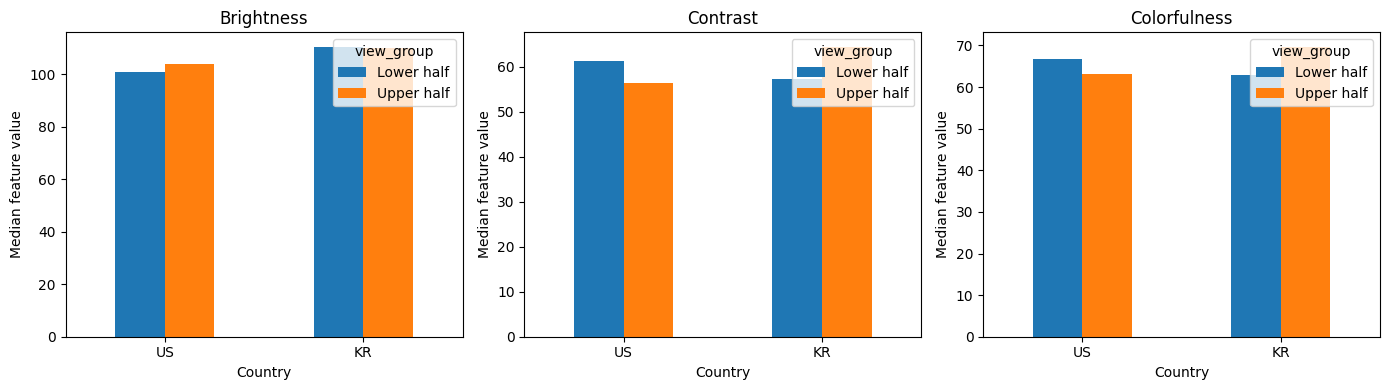

In [37]:

# Data Mining: thumbnail features vs observed views

visual_valid = thumbnail_expanded[
    thumbnail_expanded["accessible"]
].copy()

visual_valid["log_views"] = np.log1p(
    visual_valid["first_observed_views"]
)

visual_columns = [
    "brightness",
    "contrast",
    "colorfulness"
]

# Compare higher-view and lower-view groups.
group_summary = (
    visual_valid.groupby(["country", "view_group"])
    .agg(
        videos=("video_id", "size"),
        median_views=("first_observed_views", "median"),
        brightness=("brightness", "median"),
        contrast=("contrast", "median"),
        colorfulness=("colorfulness", "median")
    )
    .round(2)
)

print("Visual features by view group:")
display(group_summary)

# Spearman correlations within each country.
correlation_rows = []

for country in COUNTRIES:
    subset = visual_valid[
        visual_valid["country"] == country
    ]

    for feature in visual_columns:
        rho = subset[feature].corr(
            subset["log_views"],
            method="spearman"
        )

        correlation_rows.append({
            "country": country,
            "feature": feature,
            "spearman_rho": rho,
            "sample_size": len(subset)
        })

visual_correlations = pd.DataFrame(
    correlation_rows
)

print("\nSpearman correlations with log views:")
display(visual_correlations.round(4))

# Plot group medians.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, feature in zip(axes, visual_columns):
    plot_data = (
        visual_valid.groupby(
            ["country", "view_group"]
        )[feature]
        .median()
        .unstack()
    )

    plot_data = plot_data.reindex(
        index=COUNTRIES,
        columns=["Lower half", "Upper half"]
    )

    plot_data.plot(
        kind="bar",
        ax=ax,
        rot=0
    )

    ax.set_title(feature.capitalize())
    ax.set_xlabel("Country")
    ax.set_ylabel("Median feature value")

plt.tight_layout()
plt.show()



### Thumbnail Features and Popularity

The expanded thumbnail sample is used to compare brightness, contrast, and color variation between lower-view and higher-view Trending videos within each country.

Spearman correlations measure the associations between these image features and log-transformed first-observed view counts.

These comparisons are exploratory because the sample contains 179 accessible thumbnails and was stratified by observed views.

The findings cannot establish whether visual properties caused higher view counts. Topic, channel popularity, upload timing, and other factors may influence the observed relationships.

The analysis also cannot directly measure click-through rates or viewer retention.


In [38]:

# Data Mining: final thumbnail sample diagnostics

sample_checks = {
    "200 videos sampled": len(thumbnail_expanded) == 200,
    "No duplicate country-video pairs": not thumbnail_expanded[
        ["country", "video_id"]
    ].duplicated().any(),
    "Valid thumbnail count consistent": (
        int(thumbnail_expanded["accessible"].sum())
        == len(visual_valid)
        and 0 < len(visual_valid) <= len(thumbnail_expanded)
    ),
    "All extracted features are finite": np.isfinite(
        visual_valid[
            ["brightness", "contrast", "colorfulness"]
        ].to_numpy()
    ).all(),
    "Both countries represented": set(
        visual_valid["country"]
    ) == set(COUNTRIES)
}

print("Final thumbnail validation:")
for name, passed in sample_checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nThumbnail access rate by group:")
display(
    thumbnail_expanded.groupby(
        ["country", "view_group"]
    )["accessible"]
    .agg(["count", "sum", "mean"])
    .round(3)
)

print("\nCorrelation within each sampled view group:")
within_group_rows = []

for (country, group), subset in visual_valid.groupby(
    ["country", "view_group"]
):
    for feature in visual_columns:
        within_group_rows.append({
            "country": country,
            "view_group": group,
            "feature": feature,
            "spearman_rho": subset[feature].corr(
                subset["log_views"],
                method="spearman"
            ),
            "n": len(subset)
        })

within_group_correlations = pd.DataFrame(
    within_group_rows
)

display(within_group_correlations.round(4))


Final thumbnail validation:
200 videos sampled: PASS
No duplicate country-video pairs: PASS
Valid thumbnail count consistent: PASS
All extracted features are finite: PASS
Both countries represented: PASS

Thumbnail access rate by group:


count  sum  mean
country view_group                  
KR      Lower half     50   46  0.92
        Upper half     50   43  0.86
US      Lower half     50   44  0.88
        Upper half     50   46  0.92


Correlation within each sampled view group:


,country,view_group,feature,spearman_rho,n
0,KR,Lower half,brightness,0.0849,46
1,KR,Lower half,contrast,-0.0546,46
2,KR,Lower half,colorfulness,0.0673,46
3,KR,Upper half,brightness,0.0275,43
4,KR,Upper half,contrast,-0.3907,43
5,KR,Upper half,colorfulness,-0.2818,43
6,US,Lower half,brightness,0.0113,44
7,US,Lower half,contrast,0.3676,44
8,US,Lower half,colorfulness,0.2836,44
9,US,Upper half,brightness,0.0924,46



### Data Mining - Final Expert Review

The Data Mining phase compared regression models, explored metadata-based content topics, and examined visual characteristics of 179 accessible thumbnails.

Random Forest performed best among the three evaluated models, although its explanatory performance remained limited.

Thumbnail brightness, contrast, and color variation showed weak Spearman correlations with first-observed Trending views in the selected sample.

The final diagnostic checks sample coverage, feature validity, image availability, and within-group correlations.

The thumbnail sample was deliberately stratified by observed views. Therefore, its correlations should not be generalized to the full Trending population without further validation.

Actual video introductions, storytelling, audience retention, and click-through rates could not be directly measured. Transcript retrieval was blocked, and metadata-based topic labels are not equivalent to observed video content.

The results support exploratory associations, not causal conclusions about what makes videos popular.



## 5. Interpretation / Evaluation

### Objective

This phase evaluates what the analysis reveals about YouTube Trending videos in the United States and South Korea during 2021–2023.

The findings are based on category comparisons, title and metadata features, regression models, exploratory topic labels, and thumbnail image statistics.

The goal is to distinguish observed relationships from causal explanations and identify which aspects of video popularity remain unmeasured.

The dataset contains videos that appeared in Trending, not a representative sample of all uploaded YouTube videos.


In [39]:

# Interpretation: consolidate final results

print("1. Final model comparison")
display(
    revised_model_results.sort_values(
        "MAE (log views)"
    ).round(4)
)

best_model = revised_model_results.sort_values(
    "MAE (log views)"
).iloc[0]

baseline = revised_model_results[
    revised_model_results["Model"] == "Mean Baseline"
].iloc[0]

mae_improvement = (
    (baseline["MAE (log views)"]
     - best_model["MAE (log views)"])
    / baseline["MAE (log views)"]
) * 100

print("\nBest model:", best_model["Model"])
print("MAE improvement over baseline:",
      round(mae_improvement, 2), "%")

print("\n2. Thumbnail feature correlations")
display(
    visual_correlations.pivot(
        index="feature",
        columns="country",
        values="spearman_rho"
    ).round(4)
)

print("\n3. Metadata topic classification coverage")
display(
    refined_topic_pilot.groupby("country").agg(
        sampled=("video_id", "size"),
        classified=(
            "topic_count",
            lambda x: int((x > 0).sum())
        ),
        unclassified=(
            "topic_count",
            lambda x: int((x == 0).sum())
        )
    )
)

print("\n4. Direct video content availability")
print("Successful transcript retrievals:",
      len(pilot_transcripts))
print("Valid expanded thumbnail records:",
      int(thumbnail_expanded["accessible"].sum()))


1. Final model comparison


,Model,MAE (log views),RMSE (log views),R2
2,Random Forest,0.7200,0.9427,0.2079
1,Ridge Regression,0.7759,1.0069,0.0963
0,Mean Baseline,0.8140,1.0594,-0.0004



Best model: Random Forest
MAE improvement over baseline: 11.55 %

2. Thumbnail feature correlations


country,KR,US
feature,,
brightness,0.0180,0.0383
colorfulness,0.1022,0.0293
contrast,0.0459,0.0746



3. Metadata topic classification coverage


,sampled,classified,unclassified
country,,,
KR,10,9,1
US,10,9,1



4. Direct video content availability
Successful transcript retrievals: 14
Valid expanded thumbnail records: 179



### Interpretation - Initial Findings

The revised Random Forest model achieved the lowest error among the evaluated models, but its R² remained approximately 0.21. This suggests that the selected metadata features explain only a limited portion of the variation in first-observed Trending views.

The thumbnail analysis found generally weak overall Spearman correlations between simple image statistics and view counts in the stratified pilot sample. Some within-group correlations were larger, but their directions differed across countries and groups.

Title-based topic classification identified broad themes in 18 of 20 pilot videos. These labels were derived from metadata and were not validated against the actual video content.

Automated transcript retrieval failed for all 17 attempted videos. Therefore, the project cannot directly evaluate spoken introductions or storytelling.

The findings describe associations among selected Trending videos. They do not establish what causes videos to become popular or explain audience retention.


In [40]:

# Interpretation Review - Revision 1:
# Evaluate the final models separately for US and KR.

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_countries = model_data.loc[
    test_mask, "country"
]

country_results = []

for name, pipeline in revised_models.items():
    predictions = pd.Series(
        pipeline.predict(X_test),
        index=X_test.index
    )

    for country in COUNTRIES:
        country_idx = test_countries[
            test_countries == country
        ].index

        actual = y_test.loc[country_idx]
        predicted = predictions.loc[country_idx]

        country_results.append({
            "model": name,
            "country": country,
            "test_videos": len(country_idx),
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted)
        })

country_model_results = pd.DataFrame(country_results)

print("Final model performance by country:")
display(
    country_model_results.sort_values(
        ["country", "MAE"]
    ).round(4)
)

print("\nRandom Forest predictions by country:")
display(
    country_model_results[
        country_model_results["model"] == "Random Forest"
    ].round(4)
)

print("\nValidation:")
print(
    "Test counts match:",
    country_model_results[
        country_model_results["model"] == "Random Forest"
    ]["test_videos"].sum() == len(X_test)
)


Final model performance by country:


,model,country,test_videos,MAE,RMSE,R2
5,Random Forest,KR,4320,0.7133,0.9308,0.2258
3,Ridge Regression,KR,4320,0.7836,1.0187,0.0726
1,Mean Baseline,KR,4320,0.8869,1.1093,-0.0998
4,Random Forest,US,7908,0.7236,0.9492,0.1345
2,Ridge Regression,US,7908,0.7717,1.0004,0.0384
0,Mean Baseline,US,7908,0.7742,1.0312,-0.0215



Random Forest predictions by country:


,model,country,test_videos,MAE,RMSE,R2
4,Random Forest,US,7908,0.7236,0.9492,0.1345
5,Random Forest,KR,4320,0.7133,0.9308,0.2258



Validation:
Test counts match: True



### Interpretation Review - Revision 1

The initial evaluation reported combined model performance across the United States and South Korea.

However, combined metrics may hide differences between countries.

The revised analysis evaluates each trained model separately on US and KR test videos, without retraining or changing the test set.

Country-specific MAE, RMSE, and R² will help identify whether model performance is consistent across the two groups.

These results should not be interpreted as evidence that one country's videos are inherently more predictable. Differences in category composition, view distributions, and other factors may influence performance.


Random Forest permutation importance:


,feature,importance_mean,importance_std
8,country,0.0943,0.0050
9,category_name,0.0752,0.0026
7,publish_hour_utc,0.0478,0.0016
6,tag_count,0.0452,0.0055
0,title_length,0.0196,0.0028
1,title_word_count,0.0167,0.0017
10,publish_weekday_utc,0.0126,0.0005
3,has_exclamation,0.0075,0.0011
4,has_number,0.0074,0.0011
5,hashtag_count,0.0031,0.0009


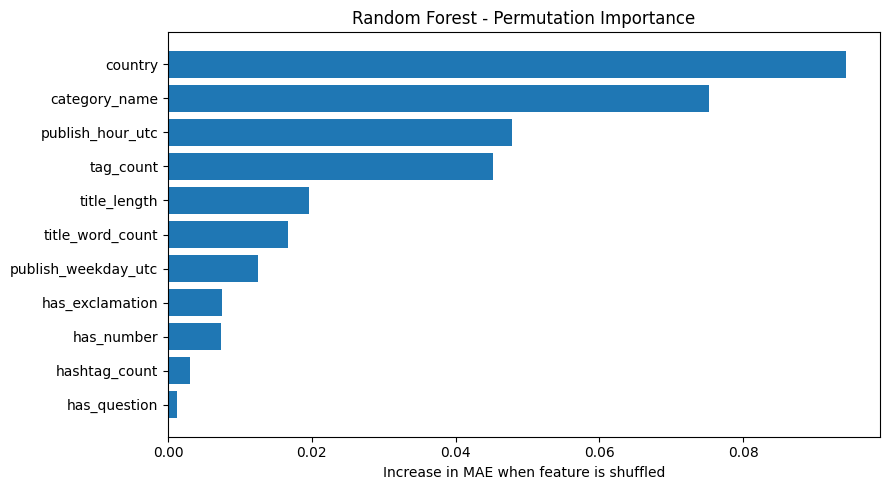


Validation:
Features evaluated: 11
Importance values finite: True


In [41]:

# Interpretation Review - Revision 2:
# Permutation importance on a reproducible test subset

from sklearn.inspection import permutation_importance

rf_final = revised_models["Random Forest"]

# Keep the evaluation efficient and reproducible.
importance_sample = X_test.sample(
    n=min(3000, len(X_test)),
    random_state=RANDOM_STATE
)

importance_target = y_test.loc[
    importance_sample.index
]

importance_result = permutation_importance(
    rf_final,
    importance_sample,
    importance_target,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)

feature_importance = pd.DataFrame({
    "feature": importance_sample.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

print("Random Forest permutation importance:")
display(feature_importance.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    feature_importance["feature"][::-1],
    feature_importance["importance_mean"][::-1]
)
plt.xlabel("Increase in MAE when feature is shuffled")
plt.title("Random Forest - Permutation Importance")
plt.tight_layout()
plt.show()

print("\nValidation:")
print("Features evaluated:", len(feature_importance))
print("Importance values finite:",
      np.isfinite(
          feature_importance["importance_mean"]
      ).all())



### Interpretation Review - Revision 2

The revised interpretation evaluates which metadata features contribute most to the Random Forest model's predictions.

Permutation importance is calculated on a reproducible subset of 3,000 held-out test videos.

Each feature is shuffled independently, and the resulting increase in prediction error is measured.

Larger positive values indicate that the trained model depends more strongly on that feature for this evaluation sample.

Permutation importance does not establish causation. Correlated features can share predictive information, and the rankings may vary with the test sample and model settings.

The findings will be interpreted as model reliance rather than as proof of what makes videos popular.


In [42]:

# Interpretation: final KDD evaluation summary

final_rf = revised_model_results.loc[
    revised_model_results["Model"] == "Random Forest"
].iloc[0]

final_baseline = revised_model_results.loc[
    revised_model_results["Model"] == "Mean Baseline"
].iloc[0]

summary = pd.DataFrame([
    {
        "Analysis": "Random Forest",
        "Evidence": f"MAE={final_rf['MAE (log views)']:.4f}, R2={final_rf['R2']:.4f}",
        "Interpretation": "Best tested model; limited explanatory power"
    },
    {
        "Analysis": "Baseline improvement",
        "Evidence": f"{mae_improvement:.2f}% lower MAE",
        "Interpretation": "Improvement on held-out test data"
    },
    {
        "Analysis": "Thumbnail statistics",
        "Evidence": f"{len(visual_valid)} valid images",
        "Interpretation": "Weak overall correlations in stratified sample"
    },
    {
        "Analysis": "Metadata topics",
        "Evidence": f"{int((refined_topic_pilot['topic_count'] > 0).sum())}/20 classified",
        "Interpretation": "Exploratory title-based labels"
    },
    {
        "Analysis": "Actual transcripts",
        "Evidence": f"{len(pilot_transcripts)} retrieved",
        "Interpretation": "Direct spoken-content analysis unavailable"
    }
])

print("Final KDD findings:")
display(summary)

final_checks = {
    "Final model metrics available":
        np.isfinite(final_rf["MAE (log views)"])
        and np.isfinite(final_rf["R2"]),
    "Random Forest beats baseline":
        final_rf["MAE (log views)"]
        < final_baseline["MAE (log views)"],
    "Country test counts match":
        country_model_results.loc[
            country_model_results["model"] == "Random Forest",
            "test_videos"
        ].sum() == len(X_test),
    "Thumbnail count consistent":
        len(visual_valid)
        == int(thumbnail_expanded["accessible"].sum()),
    "Metadata pilot count consistent":
        len(refined_topic_pilot) == 20,
    "Importance values finite":
        np.isfinite(
            feature_importance["importance_mean"]
        ).all()
}

print("\nFinal KDD validation:")
for name, passed in final_checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")


Final KDD findings:


,Analysis,Evidence,Interpretation
0,Random Forest,"MAE=0.7200, R2=0.2079",Best tested model; limited explanatory power
1,Baseline improvement,11.55% lower MAE,Improvement on held-out test data
2,Thumbnail statistics,179 valid images,Weak overall correlations in stratified sample
3,Metadata topics,18/20 classified,Exploratory title-based labels
4,Actual transcripts,14 retrieved,Direct spoken-content analysis unavailable



Final KDD validation:
Final model metrics available: PASS
Random Forest beats baseline: PASS
Country test counts match: PASS
Thumbnail count consistent: PASS
Metadata pilot count consistent: PASS
Importance values finite: PASS



### Interpretation - Final Expert Review

The KDD analysis examined 60,909 selected US and KR Trending videos from 2021–2023.

Among the evaluated regression models, Random Forest performed best, with a revised test MAE of 0.7200 and R² of 0.2079 on log-transformed first-observed views.

Country and video category were the strongest features in the permutation importance analysis. These values describe model reliance, not causal effects.

The analysis of 179 accessible high-resolution thumbnails found weak overall associations between basic image statistics and observed views in the stratified sample.

Title-based topic classification provided exploratory content labels, but direct transcript retrieval was unsuccessful. Storytelling, visual editing, click-through rates, audience retention, and cultural trend effects were not directly evaluated.

The dataset includes only videos observed in Trending. Its results should not be generalized to all uploaded YouTube videos.

Overall, metadata provides some predictive information, but the available features do not adequately explain why individual videos become popular.

The findings are exploratory and should not be used as causal recommendations for content creators.
